# Universidad de Buenos Aires
## Laboratorio de Sistemas Embebidos
## Especialización en Inteligencia Artificial

**Análisis de Series de Tiempo 1**

**Docente:** Camilo Argoty

---

**Nombre:** Franco Marcelo Morero &nbsp;&nbsp;&nbsp; **Código:** a2533

**Fecha:** 16 de Noviembre de 2026

---

### SEGUNDO TRABAJO PRÁCTICO

Simule series de tiempo que se comporten según los siguientes modelos

1. ARMA (2 puntos)
2. ARIMA (2 puntos)
3. SARIMA (2 puntos)
4. VARMA (2 puntos)
5. GARCH (2 puntos)

Elija los órdenes a voluntad. En el caso de ARIMA, el orden de integración debe ser al menos 1. En SARIMA, el orden estacional debe ser mayor que 1.

Explique el proceso para crear la simulación, de forma que quede demostrado que las series generadas cumplen con los modelos que les corresponden.

Entregar los códigos en python de forma que se puedan correr y verificar las simulaciones.

---

Cargo las librerías. La semilla del generador aleatorio la fijo al principio de cada punto, así cada simulación es reproducible y no depende de haber corrido los puntos anteriores.

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set()

import statsmodels.graphics.tsaplots as sgt
import statsmodels.tsa.stattools as sts
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.statespace.varmax import VARMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from arch import arch_model

import warnings
warnings.filterwarnings('ignore')

## Método general

Las cinco series las armo igual. Parto de la ecuación del modelo y la recorro paso a paso con un ruido blanco gaussiano sacado de `rng`, así cada valor sale de los anteriores tal como dice la ecuación. Arranco con ceros y simulo 500 pasos de más que después tiro (el burn-in), para que la serie se olvide de esa condición inicial y quede en su régimen estacionario.

Para mostrar que cada serie cumple con su modelo hago tres cosas. Primero la miro y le corro la prueba de Dickey-Fuller aumentada para ver si es estacionaria o si tiene raíz unitaria. Después comparo la ACF y la PACF muestrales con las teóricas del modelo. Y por último vuelvo a estimar el modelo sobre la serie simulada, sin decirle los parámetros, y veo si recupera los valores que usé, mirando si cada valor real cae dentro del intervalo de confianza al 95 % y si los residuos quedan como ruido blanco (ACF de residuos y prueba de Ljung-Box).

In [44]:
def adf_test(serie, titulo=''):
    print(f'Prueba de Dickey-Fuller aumentada: {titulo}')
    resultado = sts.adfuller(pd.Series(serie).dropna(), autolag='AIC')
    etiquetas = ['Estadístico ADF', 'p-valor', '# rezagos usados', '# observaciones']
    salida = pd.Series(resultado[0:4], index=etiquetas)
    for clave, valor in resultado[4].items():
        salida[f'valor crítico ({clave})'] = valor
    print(salida.to_string())
    if resultado[1] <= 0.05:
        print('... se rechaza H0, la serie no tiene raíz unitaria y es estacionaria\n')
    else:
        print('... no se rechaza H0, la serie tiene raíz unitaria y no es estacionaria\n')


def tabla_parametros(reales, res):
    # reales: {nombre del parámetro en res.params: valor usado en la simulación}
    ic = res.conf_int()
    filas = []
    for nombre, valor in reales.items():
        filas.append({
            'parámetro': nombre,
            'real': valor,
            'estimado': res.params[nombre],
            'IC 95% inf': ic.loc[nombre].iloc[0],
            'IC 95% sup': ic.loc[nombre].iloc[1],
            'real dentro del IC': ic.loc[nombre].iloc[0] <= valor <= ic.loc[nombre].iloc[1],
        })
    return pd.DataFrame(filas).set_index('parámetro').round(3)

## 1. ARMA(2,1)

### Planteo

Elijo un ARMA(2,1) sin constante, o sea que cada valor depende de los dos valores anteriores de la serie, del shock de hoy y del shock de ayer

$$X_t = \phi_1 X_{t-1} + \phi_2 X_{t-2} + \varepsilon_t + \theta_1\varepsilon_{t-1}$$

con $\phi_1 = 0{,}7$, $\phi_2 = -0{,}1$ y $\theta_1 = 0{,}5$. Acá $\varepsilon_t$ es un ruido blanco gaussiano con $\sigma = 1$, y para ruido blanco sé que

$$E(\varepsilon_t) = 0, \qquad \operatorname{Var}(\varepsilon_t) = \sigma^2, \qquad \operatorname{Cov}(\varepsilon_t, \varepsilon_s) = 0, \quad t \neq s$$

Escribiendo el modelo con el operador de rezago $L$, que cumple $L X_t = X_{t-1}$, queda $\phi(L)\,X_t = \theta(L)\,\varepsilon_t$, donde el polinomio característico autorregresivo $\phi(L)$ y el polinomio característico de media móvil $\theta(L)$ son

$$\phi(L) = I - 0{,}7L + 0{,}1L^2 = \left(I - \frac{L}{2}\right)\left(I - \frac{L}{5}\right), \qquad \theta(L) = I + 0{,}5L = I + \frac{L}{2}$$

El proceso es estacionario si las raíces del polinomio autorregresivo caen fuera del círculo unitario, y es invertible si pasa lo mismo con las raíces del polinomio de media móvil. Elegí los coeficientes para que los polinomios se factoricen fácil, así las raíces se leen directo. Las de $\phi(L)$ son 2 y 5, y la de $\theta(L)$ es $-2$. Las tres tienen módulo mayor que 1, así que se cumplen las dos condiciones.

Lo chequeo con `ArmaProcess`. Notemos que statsmodels pide los coeficientes de los polinomios tal cual, con el 1 adelante, así que los $\phi$ van con el signo cambiado y los $\theta$ con el signo propio.

In [45]:
phi1, phi2 = 0.7, -0.1
theta1 = 0.5
sigma = 1
n, burn = 1000, 500

proceso_arma = ArmaProcess(np.r_[1, -phi1, -phi2], np.r_[1, theta1])
print(f'Estacionario       : {proceso_arma.isstationary}')
print(f'Invertible         : {proceso_arma.isinvertible}')
print(f'Raíces AR          : {np.round(proceso_arma.arroots, 3)}')
print(f'Raíces MA          : {np.round(proceso_arma.maroots, 3)}')

Estacionario       : True
Invertible         : True
Raíces AR          : [2. 5.]
Raíces MA          : [-2.]


### Simulación

Saco los $n + 500$ shocks de una normal con media 0 y desvío $\sigma$, arranco con $X_0 = X_1 = 0$ y recorro la ecuación paso a paso. Después tiro los primeros 500 valores.

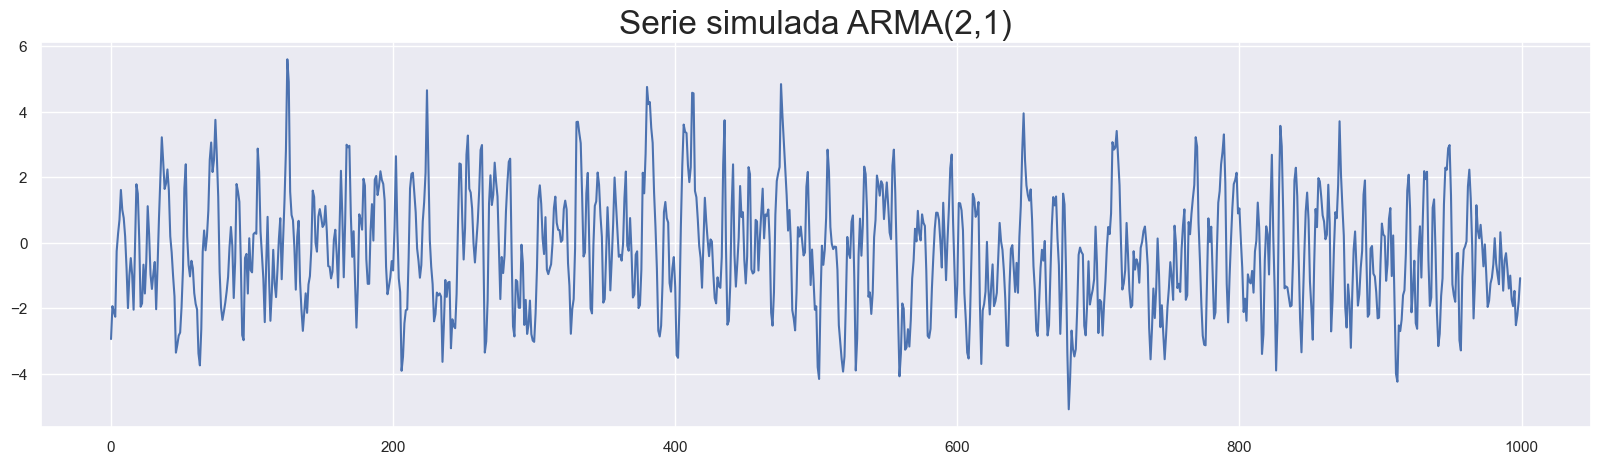

In [46]:
rng = np.random.default_rng(2)

eps = rng.normal(0, sigma, n + burn)
y = np.zeros(n + burn)
for t in range(2, n + burn):
    y[t] = phi1 * y[t - 1] + phi2 * y[t - 2] + eps[t] + theta1 * eps[t - 1]

# descarto el burn-in
serie_arma = pd.Series(y[burn:])

serie_arma.plot(figsize=(20, 5))
plt.title('Serie simulada ARMA(2,1)', size=24)
plt.show()

La serie oscila alrededor de cero sin tendencia y con una amplitud que se mantiene parecida en todo el tramo, que es lo que espero de un proceso estacionario.

### Verificación

Empiezo por la prueba de Dickey-Fuller aumentada.

In [47]:
adf_test(serie_arma, 'ARMA(2,1)')

Prueba de Dickey-Fuller aumentada: ARMA(2,1)
Estadístico ADF       -1.204275e+01
p-valor                2.708245e-22
# rezagos usados       5.000000e+00
# observaciones        9.940000e+02
valor crítico (1%)    -3.436946e+00
valor crítico (5%)    -2.864452e+00
valor crítico (10%)   -2.568321e+00
... se rechaza H0, la serie no tiene raíz unitaria y es estacionaria



El p-valor queda muy por debajo de 0,05, así que rechazo la raíz unitaria y la serie es estacionaria, como pedían las raíces del polinomio autorregresivo.

Ahora comparo la ACF y la PACF muestrales con las teóricas que salen de `ArmaProcess`. Dibujo las teóricas como puntos rojos encima de las barras muestrales.

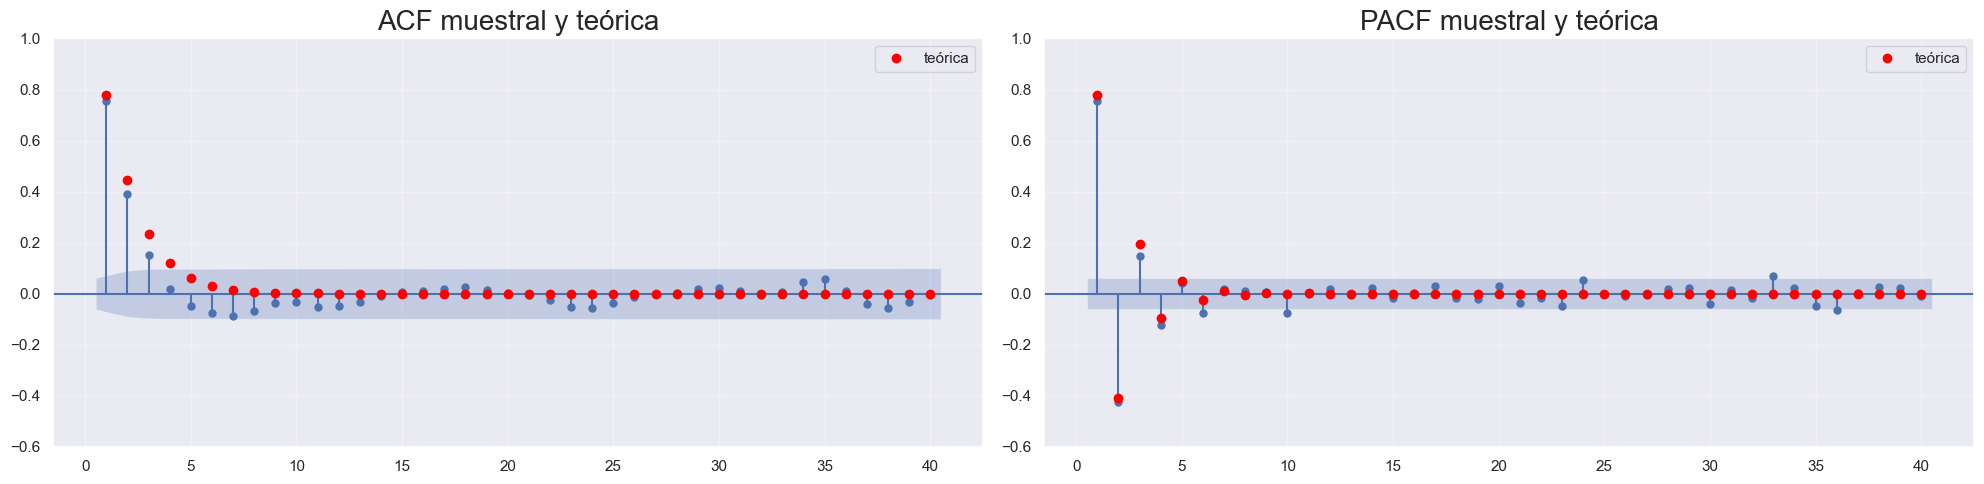

In [48]:
lags = 40
acf_teorica = proceso_arma.acf(lags + 1)[1:]
pacf_teorica = proceso_arma.pacf(lags + 1)[1:]

fig, axes = plt.subplots(1, 2, figsize=(20, 5))
sgt.plot_acf(serie_arma, lags=lags, zero=False, ax=axes[0])
axes[0].plot(range(1, lags + 1), acf_teorica, 'o', color='red', label='teórica')
axes[0].set_title('ACF muestral y teórica', size=20)
sgt.plot_pacf(serie_arma, lags=lags, zero=False, ax=axes[1], method='ywm')
axes[1].plot(range(1, lags + 1), pacf_teorica, 'o', color='red', label='teórica')
axes[1].set_title('PACF muestral y teórica', size=20)
for ax in axes:
    ax.set_ylim(-0.6, 1)
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Las barras muestrales siguen de cerca a los puntos teóricos. La ACF teórica arranca alta en el primer rezago, se mantiene positiva y en cada rezago queda más o menos en la mitad del anterior. Eso es lo que espero con raíces reales en el polinomio autorregresivo, porque el decaimiento lo manda la raíz más chica, que es 2, y no hay oscilación. La PACF tiene un pico positivo en el primer rezago y uno negativo en el segundo, pero no se corta ahí. Sigue alternando el signo y achicándose también a la mitad en cada rezago, que es la huella de la raíz $-2$ del polinomio de media móvil. Por eso ni la ACF ni la PACF solas alcanzan para leer los órdenes. Pasados los primeros rezagos casi todas las barras quedan dentro de las bandas de confianza.

Entonces estimo un ARMA(2,1) sobre la serie, sin pasarle los parámetros.

In [49]:
res_arma = ARIMA(serie_arma, order=(2, 0, 1), trend='n').fit()
res_arma.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                 1000
Model:                 ARIMA(2, 0, 1)   Log Likelihood               -1432.133
Date:                Tue, 17 Nov 2026   AIC                           2872.266
Time:                        16:49:43   BIC                           2891.897
Sample:                             0   HQIC                          2879.727
                               - 1000                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6728      0.062     10.841      0.000       0.551       0.794
ar.L2         -0.1040      0.055     -1.903      0.057      -0.211       0.003
ma.L1          0.5126      0.053      9.739      0.000       0.409       0.616
sigma2         1.0253      0.047     22.038      0.000       0.934       1.116
===================================================================================
Ljung-Box (L1) (Q):                   0.08   Jarque-Bera (JB):                 0.18
Prob(Q):                              0.77   Prob(JB):                         0.91
Heteroskedasticity (H):               1.08   Skew:                             0.02
Prob(H) (two-sided):                  0.46   Kurtosis:                         2.95
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [50]:
tabla_parametros({'ar.L1': phi1, 'ar.L2': phi2, 'ma.L1': theta1, 'sigma2': sigma**2}, res_arma)

,real,estimado,IC 95% inf,IC 95% sup,real dentro del IC
parámetro,,,,,
ar.L1,0.7,0.673,0.551,0.794,True
ar.L2,-0.1,-0.104,-0.211,0.003,True
ma.L1,0.5,0.513,0.409,0.616,True
sigma2,1.0,1.025,0.934,1.116,True


Las estimaciones quedan cerca de los valores que uso y los cuatro valores reales caen dentro de su intervalo de confianza al 95 %. Por último miro los residuos del modelo ajustado.

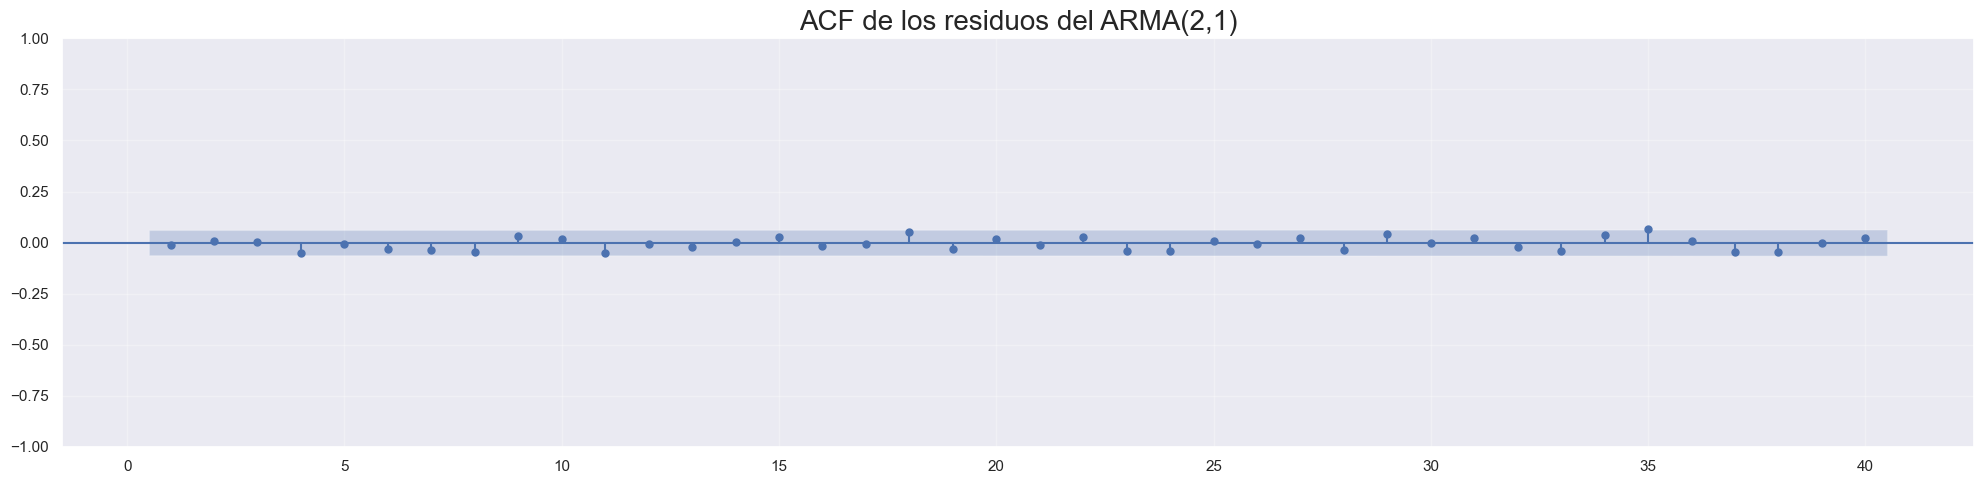

,lb_stat,lb_pvalue
10,8.667588,0.563914
20,16.903521,0.659229


In [51]:
fig, ax = plt.subplots(figsize=(20, 5))
sgt.plot_acf(res_arma.resid, lags=lags, zero=False, ax=ax)
ax.set_title('ACF de los residuos del ARMA(2,1)', size=20)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

acorr_ljungbox(res_arma.resid, lags=[10, 20])

La ACF de los residuos no muestra ningún rezago que se salga claramente de las bandas, y la prueba de Ljung-Box da p-valores altos en los rezagos 10 y 20, así que no rechazo que los residuos sean ruido blanco.

Entonces la serie que armé con la recursión es estacionaria, como pedían las raíces del polinomio autorregresivo, y su ACF y su PACF muestrales reproducen las teóricas de un ARMA(2,1) con estos coeficientes. Cuando le ajusto el modelo sin darle los parámetros recupera valores compatibles con los reales, y lo que sobra después del ajuste es ruido blanco, así que no queda dependencia que el ARMA(2,1) no explique. Con esto muestro que la serie simulada cumple con el modelo que planteé.

## 2. ARIMA(1,1,1)

### Planteo

Un ARIMA(1,1,1) es una serie $X_t$ cuya primera diferencia es un ARMA(1,1). Llamo

$$W_t = \Delta X_t = X_t - X_{t-1}$$

y pido que $W_t$ siga

$$W_t = \phi W_{t-1} + \varepsilon_t + \theta \varepsilon_{t-1}, \qquad \varepsilon_t \sim N(0, \sigma^2)$$

con $\phi = 0{,}5$, $\theta = 0{,}5$ y $\sigma = 1$. Despejando la diferencia queda $X_t = X_{t-1} + W_t$, o sea que $X_t$ es la suma acumulada de los $W_t$. Así que primero simulo el ARMA(1,1) y después lo integro una vez, y eso da un orden de integración $d = 1$, como pide la consigna.

Con el operador de rezago $L$, como en las clases, un ARIMA(p,d,q) se escribe $\phi(L)(I - L)^d X_t = \theta(L)\varepsilon_t$, donde $\phi(L)$ es el polinomio característico autorregresivo y $\theta(L)$ el de media móvil. En este caso queda

$$(I - 0{,}5L)(I - L) X_t = (I + 0{,}5L)\varepsilon_t,$$

y como $(I - L) X_t = \Delta X_t = W_t$, es lo mismo que decir $(I - 0{,}5L) W_t = (I + 0{,}5L)\varepsilon_t$.

Elegí los valores para que las raíces de los polinomios queden enteras. El factor $I - 0{,}5L$ se anula en $L = 2$, el factor $I - L$ en $L = 1$ y el polinomio de media móvil $I + 0{,}5L$ en $L = -2$. Las raíces 2 y $-2$ tienen módulo 2 y caen fuera del círculo unitario, así que $W_t$ es estacionaria e invertible. La raíz 1, que aparece al integrar, cae justo sobre el círculo. Esa es la raíz unitaria, y por ella $X_t$ no es estacionaria. Lo chequeo con `ArmaProcess`, primero sobre la parte ARMA y después sobre el polinomio autorregresivo completo de $X_t$.

In [52]:
phi, theta, sigma = 0.5, 0.5, 1.0
proceso_w = ArmaProcess(np.r_[1, -phi], np.r_[1, theta])
print(f'raíz AR de W:      {proceso_w.arroots}')
print(f'raíz MA de W:      {proceso_w.maroots}')
print(f'W estacionaria:    {proceso_w.isstationary}')
print(f'W invertible:      {proceso_w.isinvertible}')

# polinomio AR de X, (I - phi L)(I - L)
proceso_x = ArmaProcess(np.convolve([1, -phi], [1, -1]), np.r_[1, theta])
print(f'raíces AR de X:    {np.sort(proceso_x.arroots.real)}')
print(f'X estacionaria:    {proceso_x.isstationary}')

raíz AR de W:      [2.]
raíz MA de W:      [-2.]
W estacionaria:    True
W invertible:      True
raíces AR de X:    [1. 2.]
X estacionaria:    False


### Simulación

Genero el ruido, recorro la recursión de $W_t$ arrancando en cero, tiro los primeros 500 valores y recién ahí integro con `np.cumsum`. O sea que tomo $X_{-1} = 0$ y la serie arranca en $X_0 = W_0$.

In [53]:
rng = np.random.default_rng(2)
n, burn = 1000, 500

eps = rng.normal(0, sigma, n + burn)
w = np.zeros(n + burn)
for t in range(1, n + burn):
    w[t] = phi * w[t - 1] + eps[t] + theta * eps[t - 1]

w = w[burn:]
serie_arima = pd.Series(np.cumsum(w))

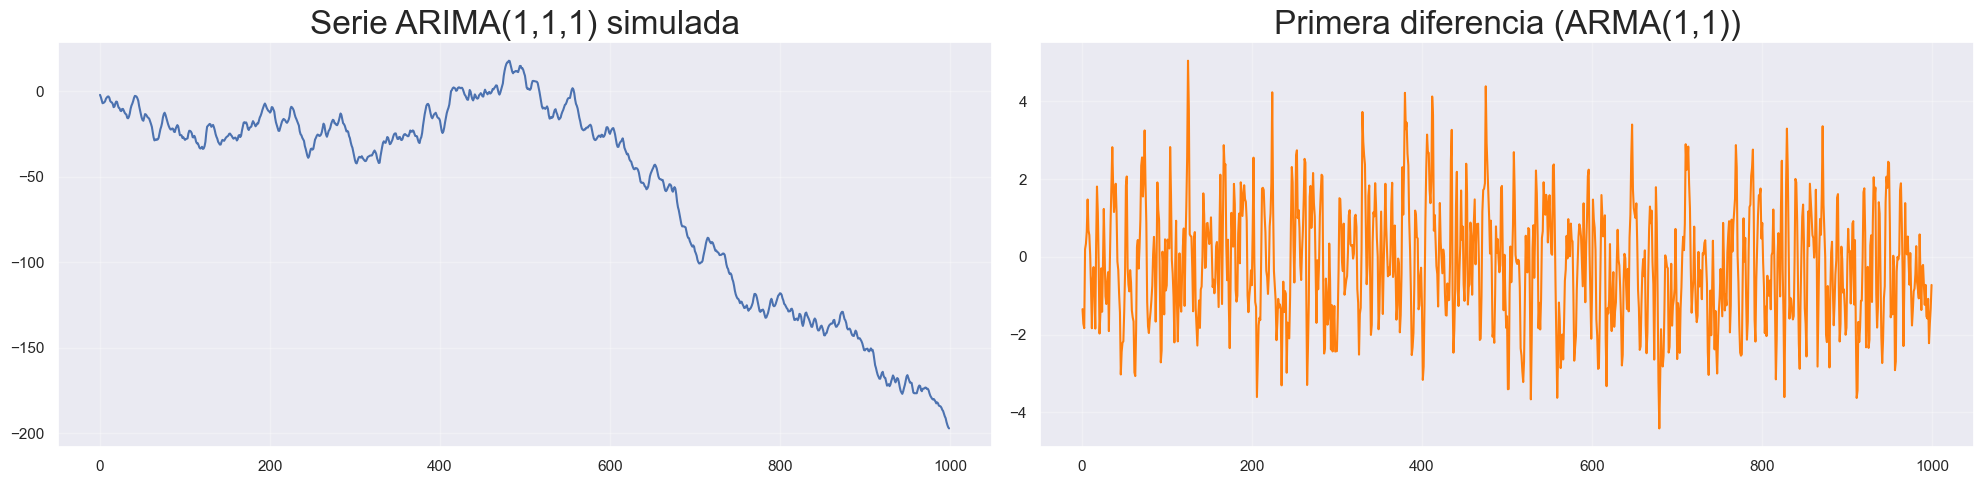

In [54]:
fig, ax = plt.subplots(1, 2, figsize=(20, 5))
ax[0].plot(serie_arima)
ax[0].set_title('Serie ARIMA(1,1,1) simulada', size=24)
ax[1].plot(serie_arima.diff(), color='tab:orange')
ax[1].set_title('Primera diferencia (ARMA(1,1))', size=24)
for a in ax:
    a.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

A simple vista ya se ve la diferencia. $X_t$ deambula sin volver a ningún nivel, como un paseo aleatorio, mientras que su diferencia oscila alrededor de cero con una varianza que no cambia en el tiempo.

### Verificación

Primero la prueba de Dickey-Fuller, sobre la serie y sobre su primera diferencia.

In [55]:
adf_test(serie_arima, 'serie ARIMA(1,1,1)')
adf_test(serie_arima.diff(), 'primera diferencia')

Prueba de Dickey-Fuller aumentada: serie ARIMA(1,1,1)
Estadístico ADF          1.243232
p-valor                  0.996271
# rezagos usados         6.000000
# observaciones        993.000000
valor crítico (1%)      -3.436953
valor crítico (5%)      -2.864455
valor crítico (10%)     -2.568322
... no se rechaza H0, la serie tiene raíz unitaria y no es estacionaria

Prueba de Dickey-Fuller aumentada: primera diferencia
Estadístico ADF       -1.226868e+01
p-valor                8.740875e-23
# rezagos usados       5.000000e+00
# observaciones        9.930000e+02
valor crítico (1%)    -3.436953e+00
valor crítico (5%)    -2.864455e+00
valor crítico (10%)   -2.568322e+00
... se rechaza H0, la serie no tiene raíz unitaria y es estacionaria



Sobre la serie no se rechaza la raíz unitaria y sobre la diferencia sí se rechaza. Es lo que esperaba de una serie integrada de orden 1, porque hace falta diferenciarla una vez, y solo una, para llegar a algo estacionario.

Ahora las autocorrelaciones. Para la diferencia superpongo los valores teóricos del ARMA(1,1), que salen de `ArmaProcess`.

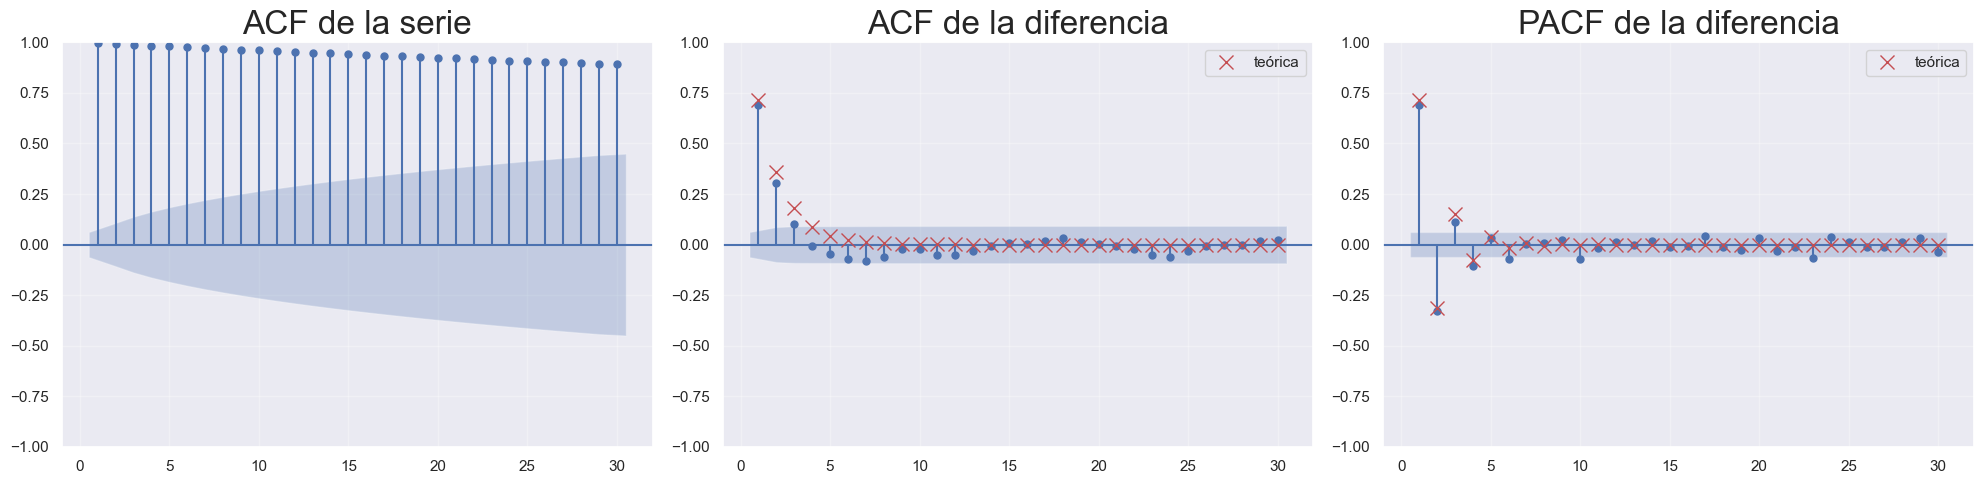

In [56]:
lags = 30
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
sgt.plot_acf(serie_arima, lags=lags, zero=False, ax=ax[0])
ax[0].set_title('ACF de la serie', size=24)
sgt.plot_acf(serie_arima.diff().dropna(), lags=lags, zero=False, ax=ax[1])
ax[1].plot(range(1, lags + 1), proceso_w.acf(lags + 1)[1:], 'rx', markersize=10, label='teórica')
ax[1].set_title('ACF de la diferencia', size=24)
sgt.plot_pacf(serie_arima.diff().dropna(), lags=lags, zero=False, method='ywm', ax=ax[2])
ax[2].plot(range(1, lags + 1), proceso_w.pacf(lags + 1)[1:], 'rx', markersize=10, label='teórica')
ax[2].set_title('PACF de la diferencia', size=24)
for a in ax:
    a.grid(True, alpha=0.3)
ax[1].legend(); ax[2].legend()
plt.tight_layout(); plt.show()

La ACF de $X_t$ arranca cerca de uno y baja muy despacio, casi en línea recta, que es la marca típica de una serie no estacionaria. La de la diferencia, en cambio, cae rápido y sigue a la teórica del ARMA(1,1). La PACF también acompaña a la teórica, que tiene un pico grande en el rezago 1 y después valores que alternan de signo y se achican más o menos a la mitad en cada rezago.

Por último estimo un ARIMA(1,1,1) directamente sobre $X_t$, sin pasarle los parámetros. La diferenciación la hace el modelo, yo no le paso $W_t$.

In [57]:
res_arima = ARIMA(serie_arima, order=(1, 1, 1)).fit()
res_arima.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                 1000
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -1429.854
Date:                Tue, 17 Nov 2026   AIC                           2865.708
Time:                        16:49:43   BIC                           2880.428
Sample:                             0   HQIC                          2871.303
                               - 1000                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4609      0.038     12.181      0.000       0.387       0.535
ma.L1          0.5215      0.034     15.434      0.000       0.455       0.588
sigma2         1.0240      0.046     22.045      0.000       0.933       1.115
===================================================================================
Ljung-Box (L1) (Q):                   0.02   Jarque-Bera (JB):                 0.19
Prob(Q):                              0.88   Prob(JB):                         0.91
Heteroskedasticity (H):               1.09   Skew:                             0.02
Prob(H) (two-sided):                  0.42   Kurtosis:                         2.95
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [58]:
tabla_parametros({'ar.L1': phi, 'ma.L1': theta, 'sigma2': sigma**2}, res_arima)

,real,estimado,IC 95% inf,IC 95% sup,real dentro del IC
parámetro,,,,,
ar.L1,0.5,0.461,0.387,0.535,True
ma.L1,0.5,0.521,0.455,0.588,True
sigma2,1.0,1.024,0.933,1.115,True


Los tres valores que uso para simular caen dentro de sus intervalos de confianza al 95 %. Falta ver que los residuos queden como ruido blanco. Saco el primer residuo, porque con $d = 1$ no hay observación anterior para diferenciar y ese residuo termina siendo casi el valor inicial de la serie, que no tiene sentido como error de predicción.

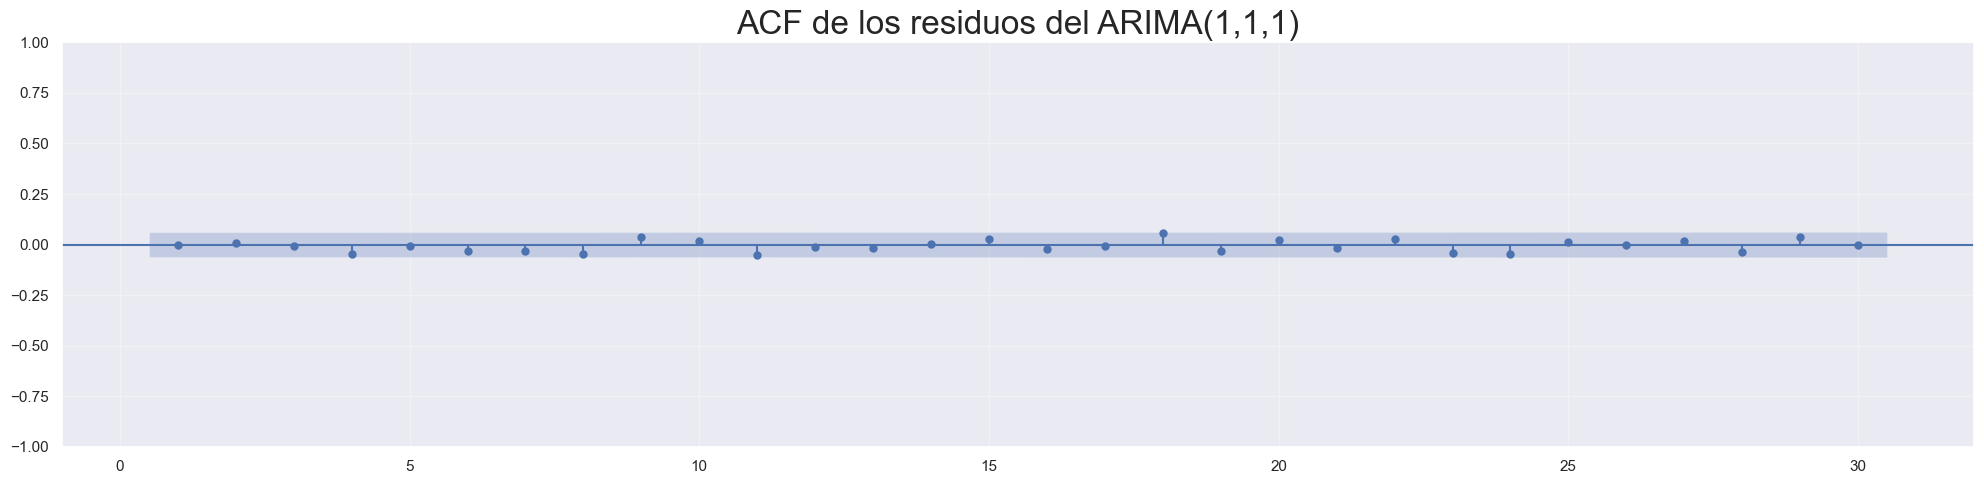

,lb_stat,lb_pvalue
10,8.453569,0.584623
20,17.072966,0.648231


In [59]:
residuos = res_arima.resid.iloc[1:]
fig, ax = plt.subplots(figsize=(20, 5))
sgt.plot_acf(residuos, lags=lags, zero=False, ax=ax)
ax.set_title('ACF de los residuos del ARIMA(1,1,1)', size=24)
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

acorr_ljungbox(residuos, lags=[10, 20])

Ninguna autocorrelación de los residuos se sale de las bandas y la prueba de Ljung-Box no rechaza la hipótesis de ruido blanco ni con 10 ni con 20 rezagos. Entonces el modelo no dejó estructura sin explicar.

Juntando todo, la serie que armé se porta como un ARIMA(1,1,1). Tiene raíz unitaria y una ACF que casi no decae, pero alcanza con diferenciarla una vez para que se vuelva estacionaria, y esa diferencia tiene la ACF y la PACF de un ARMA(1,1) con los parámetros que elegí. Además, cuando le estimo el modelo a la serie integrada recupero $\phi$, $\theta$ y $\sigma^2$ dentro de sus intervalos, y lo que queda sin explicar es ruido blanco.

## 3. SARIMA(1,0,0)(2,1,0)₁₂

### Planteo

Tomo una serie mensual, con período estacional $s=12$, y le pongo un AR(1) regular, una parte autorregresiva estacional de orden $P=2$ y una diferencia estacional $D=1$.

Con el operador de rezago $L$ y la diferencia estacional $\Delta_s X_t=X_t-X_{t-s}=(I-L^s)X_t$, el SARIMA general se escribe $\phi(L)\Phi(L)(I-L)^d(I-L^s)^D X_t=\theta(L)\Theta(L)\varepsilon_t$. En este caso no hay parte de media móvil ni diferencia regular, así que el modelo queda

$$\phi(L)\,\Phi(L)\,(I-L^{12})\,X_t=\varepsilon_t, \qquad \phi(L)=I-\phi L, \qquad \Phi(L)=I-\Phi_1 L^{12}-\Phi_2 L^{24}, \qquad \varepsilon_t \sim N(0,\sigma^2)$$

donde $\phi(L)$ es el polinomio característico autorregresivo regular y $\Phi(L)$ el estacional, con $\phi=0{,}5$, $\Phi_1=0{,}75$, $\Phi_2=-0{,}125$ y $\sigma=1$. El regular $\phi(z)=1-0{,}5z$ tiene raíz 2, y el estacional se factoriza como $1-0{,}75x+0{,}125x^2=(1-x/2)(1-x/4)$ con $x=L^{12}$, así que sus raíces en $x$ son 2 y 4. La diferencia estacional $I-L^{12}$ aporta 12 raíces de módulo 1, que son la raíz unitaria estacional. Esa parte la puedo separar. Si defino $W_t=\Delta_{12}X_t=X_t-X_{t-12}$, entonces $W_t$ sigue el AR estacionario

$$\phi(L)\,\Phi(L)\,W_t=(I-\phi L)(I-\Phi_1 L^{12}-\Phi_2 L^{24})\,W_t=\varepsilon_t.$$

Al multiplicar los dos polinomios queda $I-\phi L-\Phi_1L^{12}+\phi\Phi_1L^{13}-\Phi_2L^{24}+\phi\Phi_2L^{25}$, que con estos valores es $I-0{,}5L-0{,}75L^{12}+0{,}375L^{13}+0{,}125L^{24}-0{,}0625L^{25}$, así que solo aparecen los rezagos 1, 12, 13, 24 y 25. O sea que $W_t$ es un AR(25) con casi todos los coeficientes en cero, y despejando tengo

$$W_t=\phi W_{t-1}+\Phi_1 W_{t-12}-\phi\Phi_1 W_{t-13}+\Phi_2 W_{t-24}-\phi\Phi_2 W_{t-25}+\varepsilon_t.$$

Para que $W_t$ sea estacionario alcanza con que las raíces de los dos polinomios queden fuera del círculo unitario. Con la raíz 2 del regular y las raíces 2 y 4 del estacional en $L^{12}$ eso ya se cumple, porque las raíces duodécimas de 2 y de 4 también tienen módulo mayor que 1. Lo verifico armando el polinomio completo con `np.polymul`.

In [60]:
phi, Phi1, Phi2 = 0.5, 0.75, -0.125
sigma = 1.0
s = 12

poly_reg = np.array([1, -phi])
poly_est = np.zeros(2 * s + 1)
poly_est[[0, s, 2 * s]] = [1, -Phi1, -Phi2]
poly_ar = np.polymul(poly_reg, poly_est)

for k in np.nonzero(poly_ar)[0]:
    print(f'rezago {k:>2}   coeficiente en el polinomio = {poly_ar[k]:>6.2f}')
print(f'\nraíces en x = L^12      {np.sort(np.roots(poly_est[[2 * s, s, 0]]))}')
print(f'¿W es estacionario?     {ArmaProcess(poly_ar, [1]).isstationary}')

rezago  0   coeficiente en el polinomio =   1.00
rezago  1   coeficiente en el polinomio =  -0.50
rezago 12   coeficiente en el polinomio =  -0.75
rezago 13   coeficiente en el polinomio =   0.38
rezago 24   coeficiente en el polinomio =   0.12
rezago 25   coeficiente en el polinomio =  -0.06

raíces en x = L^12      [2. 4.]
¿W es estacionario?     True


El polinomio tiene justo los coeficientes de la expansión, que en la ecuación de $W_t$ aparecen con el signo cambiado porque pasan del lado derecho. Las raíces de $\Phi$ en $L^{12}$ son 2 y 4, y el proceso $W_t$ es estacionario.

### Simulación

Primero simulo $W_t$ con la recursión del AR(25), usando directamente el vector de coeficientes del polinomio, con un burn-in de 504 pasos (42 años) que después tiro. Luego integro estacionalmente con $X_t=W_t+X_{t-12}$, o sea que cada valor de $X_t$ es el del mismo mes del año anterior más $W_t$. Para los primeros 12 meses no hay año anterior, así que ahí tomo $X_t=W_t$.

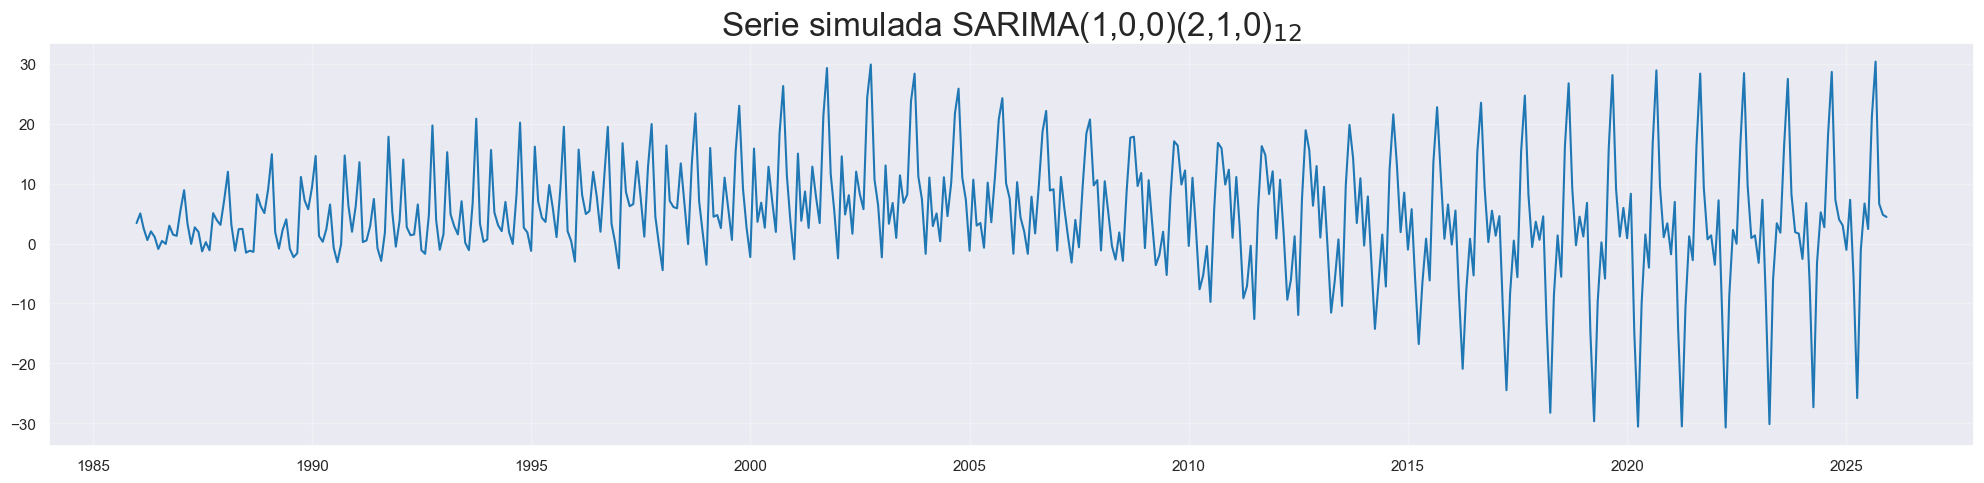

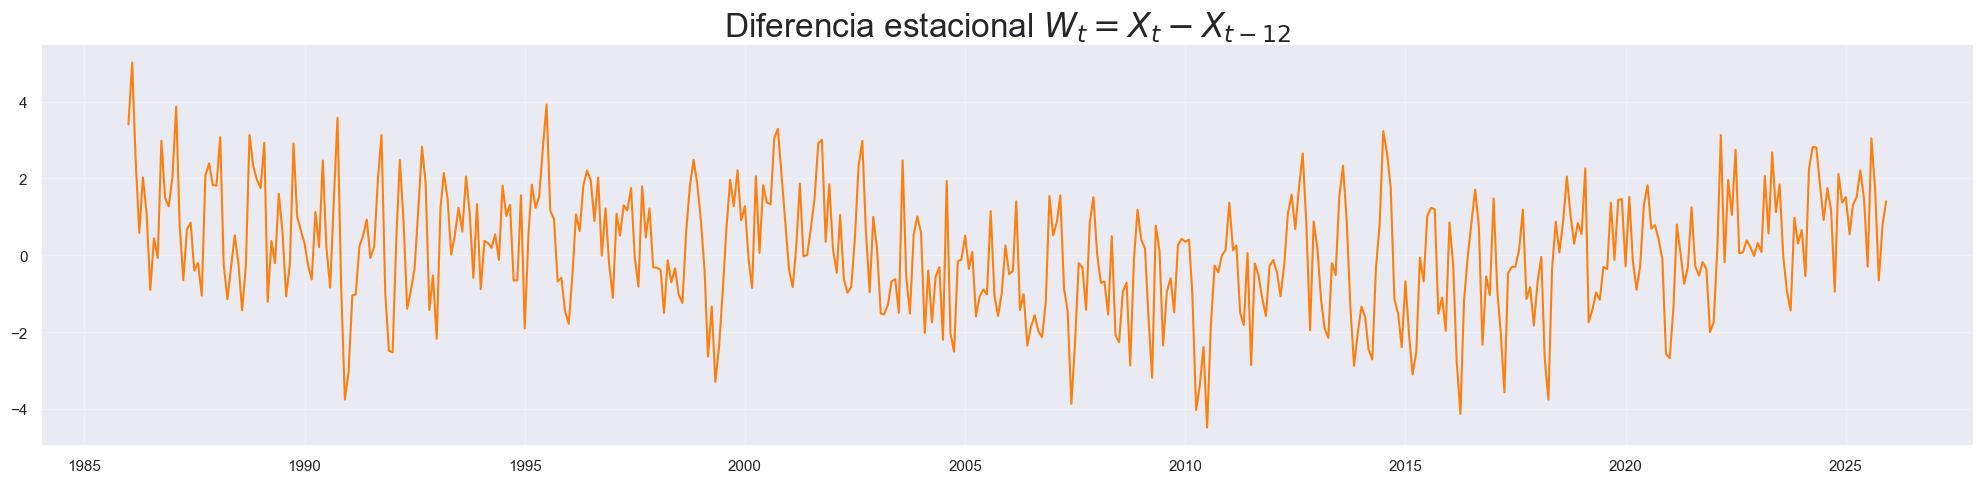

In [61]:
rng = np.random.default_rng(3)

n = 480       # 40 años mensuales
burn = 504
p = len(poly_ar) - 1   # 25

eps = rng.normal(0, sigma, n + burn)
w = np.zeros(n + burn)
for t in range(p, n + burn):
    # W_t = -(a_1 W_{t-1} + ... + a_25 W_{t-25}) + eps_t
    w[t] = eps[t] - np.dot(poly_ar[1:], w[t - p:t][::-1])
w = w[burn:]

# integración estacional
y = w.copy()
for t in range(s, n):
    y[t] = w[t] + y[t - s]

fechas = pd.date_range('1986-01', periods=n, freq='MS')
serie_sarima = pd.Series(y, index=fechas)
w_sarima = pd.Series(w, index=fechas)

fig, ax = plt.subplots(figsize=(20, 5))
ax.plot(serie_sarima, color='tab:blue')
ax.set_title('Serie simulada SARIMA(1,0,0)(2,1,0)$_{12}$', size=24)
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(20, 5))
ax.plot(w_sarima, color='tab:orange')
ax.set_title('Diferencia estacional $W_t = X_t - X_{t-12}$', size=24)
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

La serie $X_t$ deambula sin volver a un nivel fijo y cada mes va por su lado, porque con la integración estacional cada mes acumula los shocks de los años anteriores. En cambio $W_t$ oscila alrededor de cero con una varianza estable, como corresponde a un proceso estacionario.

### Verificación

Corro Dickey-Fuller sobre $X_t$ y sobre su diferencia estacional.

In [62]:
adf_test(serie_sarima, 'SARIMA, serie X')
adf_test(serie_sarima.diff(s), 'SARIMA, diferencia estacional W')

Prueba de Dickey-Fuller aumentada: SARIMA, serie X
Estadístico ADF         -1.069588
p-valor                  0.727046
# rezagos usados        12.000000
# observaciones        467.000000
valor crítico (1%)      -3.444431
valor crítico (5%)      -2.867749
valor crítico (10%)     -2.570077
... no se rechaza H0, la serie tiene raíz unitaria y no es estacionaria

Prueba de Dickey-Fuller aumentada: SARIMA, diferencia estacional W
Estadístico ADF         -3.000389
p-valor                  0.034858
# rezagos usados        12.000000
# observaciones        455.000000
valor crítico (1%)      -3.444804
valor crítico (5%)      -2.867913
valor crítico (10%)     -2.570165
... se rechaza H0, la serie no tiene raíz unitaria y es estacionaria



Sobre $X_t$ no se rechaza la raíz unitaria y sobre la diferencia estacional sí, así que con una diferencia estacional la serie queda estacionaria, que es lo que dice $D=1$. Notemos igual que ADF busca solo la raíz unitaria en $z=1$. Como $I-L^{12}=(I-L)(I+L+\dots+L^{11})$, la diferencia estacional contiene esa raíz y por eso la prueba la detecta en $X_t$, pero las otras 11 raíces estacionales quedan fuera de lo que mira. La evidencia más directa de la raíz estacional la da la ACF de $X_t$.

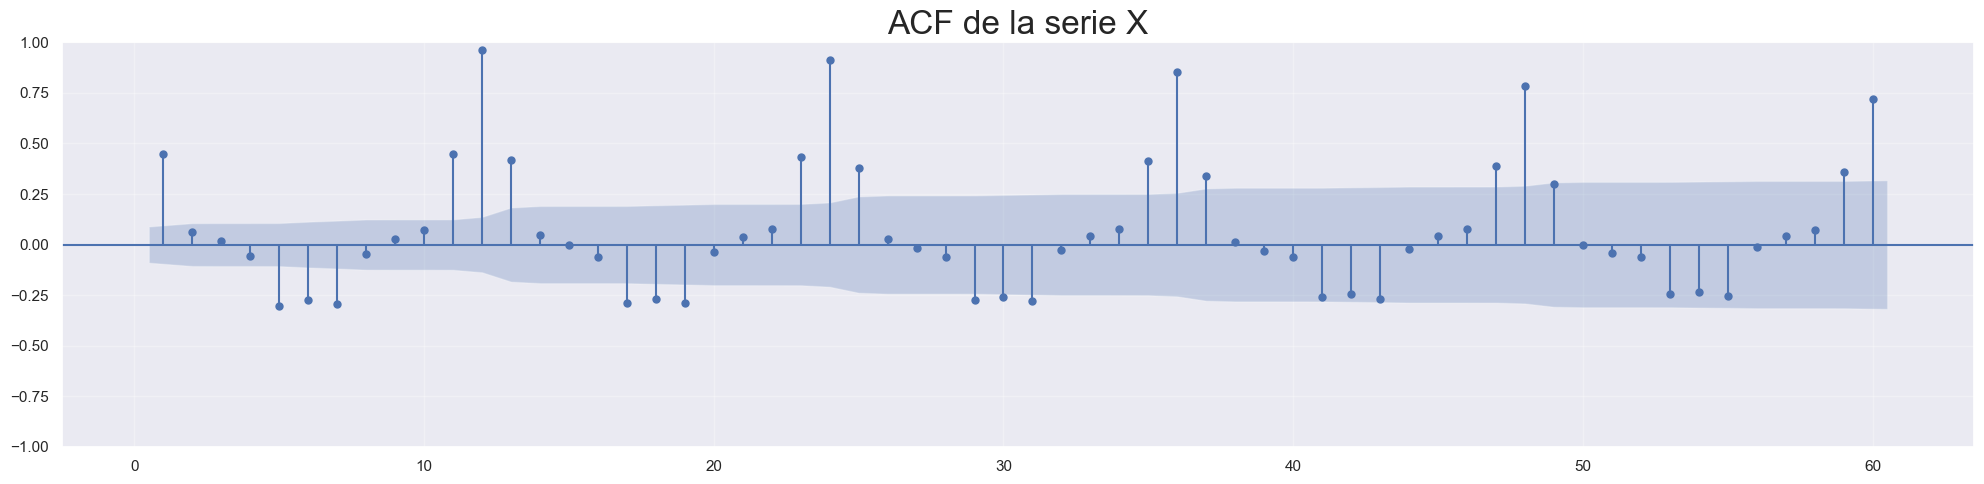

In [63]:
fig, ax = plt.subplots(figsize=(20, 5))
sgt.plot_acf(serie_sarima, lags=60, zero=False, ax=ax)
ax.set_title('ACF de la serie X', size=24)
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

La ACF de $X_t$ tiene picos en 12, 24, 36 y 48 que bajan muy despacio, que es lo típico de una raíz unitaria estacional. Ahora comparo la ACF y la PACF muestrales de $W_t$ con las teóricas del AR(25), que saco de `ArmaProcess` y marco con puntos rojos.

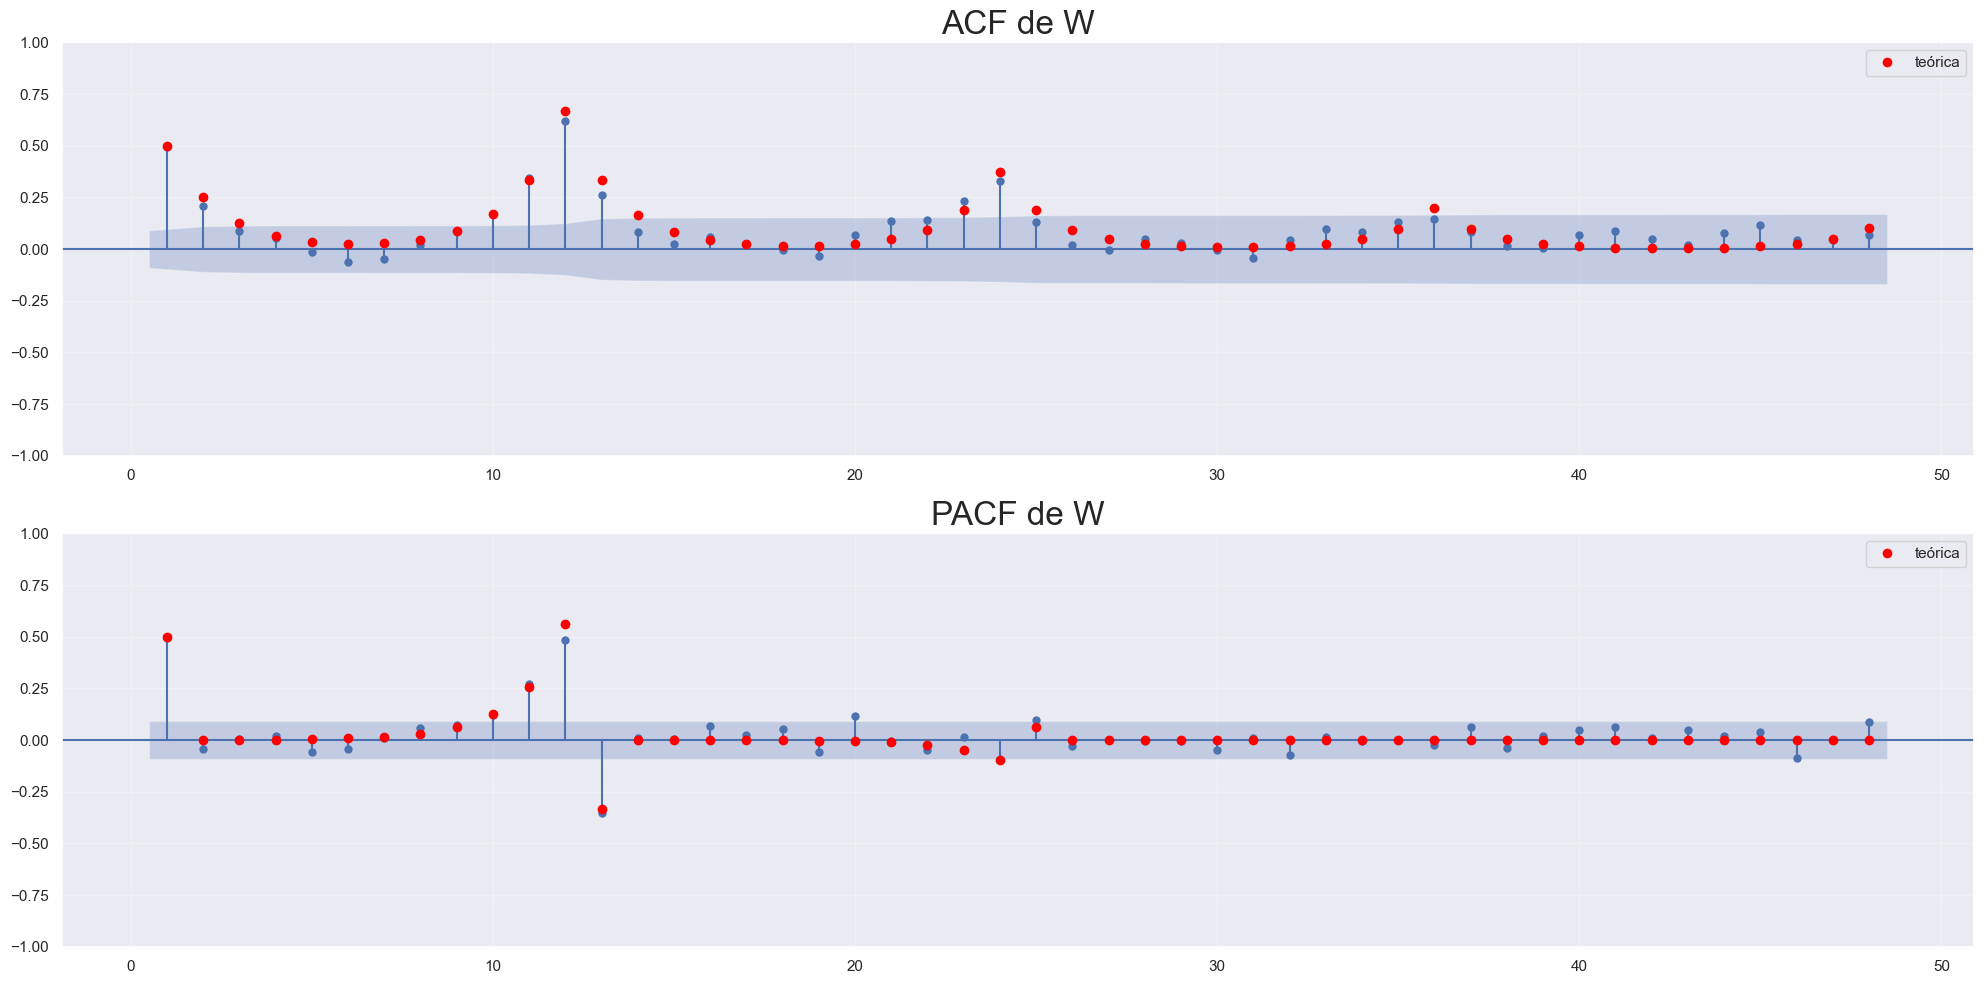

In [64]:
proceso_w = ArmaProcess(poly_ar, [1])
lags = 48
acf_teo = proceso_w.acf(lags + 1)[1:]
pacf_teo = proceso_w.pacf(lags + 1)[1:]
w_dif = serie_sarima.diff(s).dropna()

fig, ax = plt.subplots(2, 1, figsize=(20, 10))
sgt.plot_acf(w_dif, lags=lags, zero=False, ax=ax[0])
ax[0].plot(range(1, lags + 1), acf_teo, 'o', color='red', label='teórica')
ax[0].set_title('ACF de W', size=24)
sgt.plot_pacf(w_dif, lags=lags, zero=False, method='ywm', ax=ax[1])
ax[1].plot(range(1, lags + 1), pacf_teo, 'o', color='red', label='teórica')
ax[1].set_title('PACF de W', size=24)
for a in ax:
    a.legend()
    a.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

Las muestrales siguen de cerca a las teóricas. La PACF tiene picos grandes en 1, 12 y 13, que son los rezagos del polinomio expandido. Antes del 12 la teórica crece un poco hacia el rezago 11 y la muestral la acompaña. La ACF tiene picos en 12, 24, 36 y 48 que bajan despacio y son todos positivos, porque las dos raíces de $\Phi$ son reales y positivas.

Por último ajusto el SARIMA(1,0,0)(2,1,0)₁₂ sobre $X_t$ sin pasarle los parámetros. En statsmodels `ar.S.L12` y `ar.S.L24` son $\Phi_1$ y $\Phi_2$ con el mismo signo que en la ecuación del planteo, así que los comparo directo con los valores reales.

In [65]:
res_sarima = SARIMAX(serie_sarima, order=(1, 0, 0), seasonal_order=(2, 1, 0, s)).fit(disp=False)
res_sarima.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                                  y   No. Observations:                  480
Model:             SARIMAX(1, 0, 0)x(2, 1, 0, 12)   Log Likelihood                -673.372
Date:                            Tue, 17 Nov 2026   AIC                           1354.744
Time:                                    16:49:45   BIC                           1371.338
Sample:                                01-01-1986   HQIC                          1361.274
                                     - 12-01-2025                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5104      0.041     12.455      0.000       0.430       0.591
ar.S.L12       0.7279      0.048     15.038      0.000       0.633       0.823
ar.S.L24      -0.1376      0.048     -2.866      0.004      -0.232      -0.043
sigma2         1.0249      0.070     14.633      0.000       0.888       1.162
===================================================================================
Ljung-Box (L1) (Q):                   0.11   Jarque-Bera (JB):                 0.64
Prob(Q):                              0.74   Prob(JB):                         0.73
Heteroskedasticity (H):               1.00   Skew:                            -0.08
Prob(H) (two-sided):                  1.00   Kurtosis:                         2.92
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [66]:
tabla_parametros({'ar.L1': phi, 'ar.S.L12': Phi1, 'ar.S.L24': Phi2, 'sigma2': sigma**2}, res_sarima)

,real,estimado,IC 95% inf,IC 95% sup,real dentro del IC
parámetro,,,,,
ar.L1,0.500,0.510,0.430,0.591,True
ar.S.L12,0.750,0.728,0.633,0.823,True
ar.S.L24,-0.125,-0.138,-0.232,-0.043,True
sigma2,1.000,1.025,0.888,1.162,True


Los cuatro valores reales caen dentro de su intervalo de confianza al 95 %. Falta ver que los residuos sean ruido blanco. Descarto los primeros 12, porque en esos meses no hay año anterior contra el cual diferenciar. El modelo los arranca con una inicialización difusa, así que su residuo es directamente el valor de la serie y no un shock.

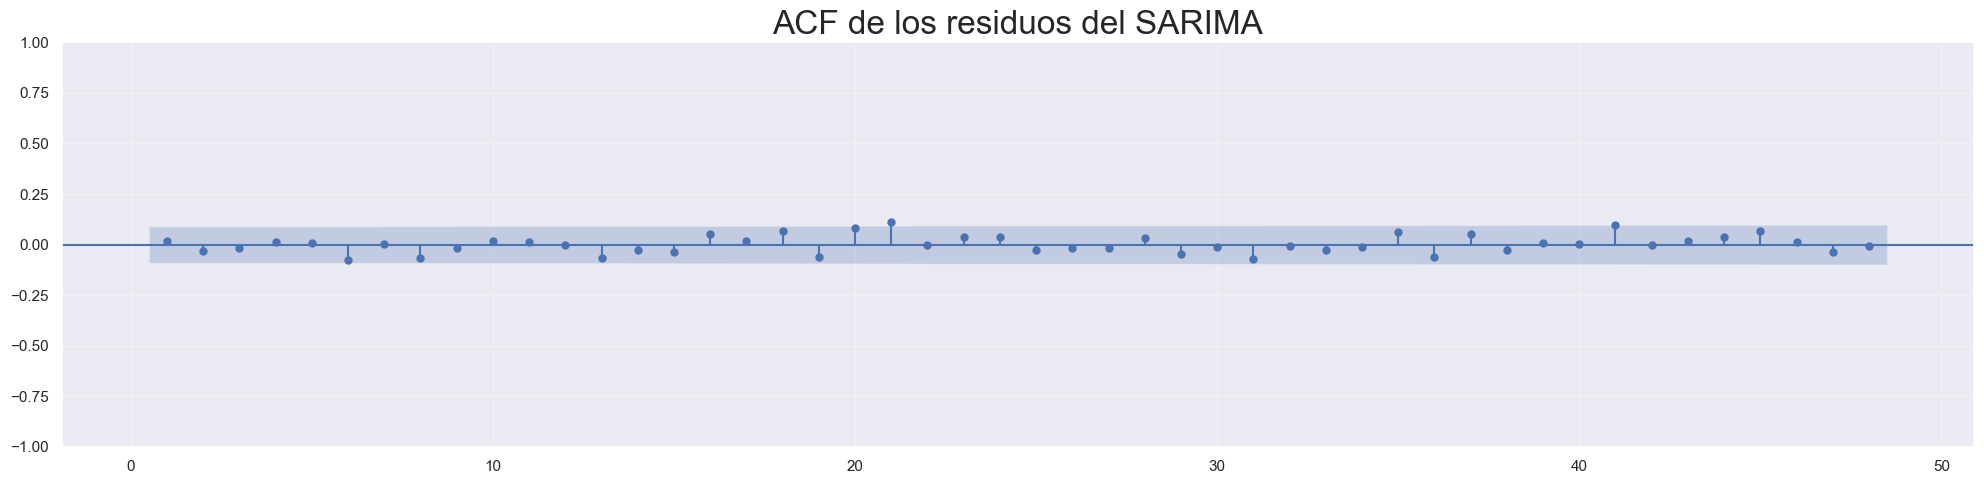

,lb_stat,lb_pvalue
12,6.160311,0.907786
24,25.418525,0.383311


In [67]:
resid_sarima = res_sarima.resid.iloc[s:]

fig, ax = plt.subplots(figsize=(20, 5))
sgt.plot_acf(resid_sarima, lags=48, zero=False, ax=ax)
ax.set_title('ACF de los residuos del SARIMA', size=24)
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

acorr_ljungbox(resid_sarima, lags=[12, 24])

La ACF de los residuos queda dentro de las bandas en los rezagos estacionales 12 y 24, y como mucho algún rezago suelto se pasa apenas, cosa esperable al mirar 48 rezagos. La prueba de Ljung-Box no rechaza la hipótesis de ruido blanco en ninguno de los dos rezagos.

Entonces la serie simulada cumple con el SARIMA(1,0,0)(2,1,0)₁₂. Tiene una raíz unitaria estacional, que se ve en la ACF de $X_t$ y desaparece al tomar la diferencia estacional, y esa diferencia se comporta como el AR(25) que sale de multiplicar los dos polinomios, con los picos de la PACF en los rezagos del polinomio expandido. Y cuando vuelvo a estimar el modelo, $\phi$, $\Phi_1$, $\Phi_2$ y $\sigma^2$ caen dentro de sus intervalos y los residuos quedan como ruido blanco.

## 4. VARMA(1,1)

### Planteo

Ahora paso a dos series que se mueven juntas. Simulo un VARMA(1,1) bivariado, o sea con $k=2$ variables y media cero,

$$\bar X_t = \Phi_1 \bar X_{t-1} + \bar\varepsilon_t + \Theta_1 \bar\varepsilon_{t-1}, \qquad \bar X_t = \begin{pmatrix} X_t \\ Y_t \end{pmatrix}, \qquad \bar\varepsilon_t = \begin{pmatrix} \varepsilon_{1,t} \\ \varepsilon_{2,t} \end{pmatrix} \sim N(\bar 0, \Sigma)$$

con

$$\Phi_1 = \begin{pmatrix} 0{,}4 & 0{,}1 \\ 0{,}15 & 0{,}35 \end{pmatrix}, \qquad \Theta_1 = \begin{pmatrix} 0{,}5 & 0 \\ 0 & 0{,}25 \end{pmatrix}, \qquad \Sigma = \begin{pmatrix} 1 & 0{,}5 \\ 0{,}5 & 1 \end{pmatrix}.$$

Escrito ecuación por ecuación queda

$$X_t = 0{,}4\,X_{t-1} + 0{,}1\,Y_{t-1} + \varepsilon_{1,t} + 0{,}5\,\varepsilon_{1,t-1}$$

$$Y_t = 0{,}15\,X_{t-1} + 0{,}35\,Y_{t-1} + \varepsilon_{2,t} + 0{,}25\,\varepsilon_{2,t-1}$$

En el código guardo $X_t$ en la columna `y1` y $Y_t$ en la columna `y2`, porque statsmodels arma los nombres de los parámetros a partir de los nombres de las columnas.

Si $\Phi_1$, $\Theta_1$ y $\Sigma$ fueran diagonales tendría dos ARMA(1,1) independientes. Acá los elementos fuera de la diagonal de $\Phi_1$ hacen que cada variable dependa de su propio rezago y también del rezago de la otra, así que lo que pasa hoy en $X_t$ llega a $Y_t$ en el período siguiente y al revés. Además los shocks de las dos ecuaciones están correlacionados en el mismo instante, porque $\Sigma$ tiene una covarianza de 0,5 fuera de la diagonal.

Con el operador rezago $L$ el modelo se escribe $(I - \Phi_1 L)\,\bar X_t = (I + \Theta_1 L)\,\bar\varepsilon_t$. Igual que en el caso univariado, el proceso es estacionario si las raíces de $\det(I - \Phi_1 L) = 0$ caen fuera del círculo unitario, y es invertible si pasa lo mismo con las de $\det(I + \Theta_1 L) = 0$. Es lo mismo que pedir que los autovalores de $\Phi_1$ y de $\Theta_1$ tengan módulo menor que 1, porque cada raíz es la inversa de un autovalor. Para $\Phi_1$ tengo traza 0,75 y determinante $0{,}4 \cdot 0{,}35 - 0{,}1 \cdot 0{,}15 = 0{,}125$, así que

$$\det(I - \Phi_1 L) = 1 - 0{,}75\,L + 0{,}125\,L^2 = (1 - 0{,}5\,L)(1 - 0{,}25\,L),$$

con autovalores 0,5 y 0,25 y raíces $L = 2$ y $L = 4$. Como $\Theta_1$ es diagonal,

$$\det(I + \Theta_1 L) = (1 + 0{,}5\,L)(1 + 0{,}25\,L),$$

con autovalores 0,5 y 0,25 y raíces $L = -2$ y $L = -4$. Las cuatro raíces tienen módulo mayor que 1. Igual las calculo en el código, junto con los autovalores.

In [68]:
Phi1 = np.array([[0.4, 0.1],
                 [0.15, 0.35]])
Theta1 = np.array([[0.5, 0.0],
                   [0.0, 0.25]])
Sigma = np.array([[1.0, 0.5],
                  [0.5, 1.0]])

print(f'Autovalores de Phi1:   {np.linalg.eigvals(Phi1)}   módulos: {np.abs(np.linalg.eigvals(Phi1))}')
print(f'Autovalores de Theta1: {np.linalg.eigvals(Theta1)}   módulos: {np.abs(np.linalg.eigvals(Theta1))}')

# det(I - Phi1 L) = 1 - tr(Phi1) L + det(Phi1) L^2 y det(I + Theta1 L) = 1 + tr(Theta1) L + det(Theta1) L^2
print(f'Raíces de det(I - Phi1 L):   {np.roots([np.linalg.det(Phi1), -np.trace(Phi1), 1])}')
print(f'Raíces de det(I + Theta1 L): {np.roots([np.linalg.det(Theta1), np.trace(Theta1), 1])}')

Autovalores de Phi1:   [0.5  0.25]   módulos: [0.5  0.25]
Autovalores de Theta1: [0.5  0.25]   módulos: [0.5  0.25]
Raíces de det(I - Phi1 L):   [4. 2.]
Raíces de det(I + Theta1 L): [-4. -2.]


Los autovalores tienen módulo menor que 1 y las raíces dan 2, 4, $-2$ y $-4$, todas fuera del círculo unitario, así que el proceso es estacionario e invertible.

### Simulación

Primero saco los shocks $\bar\varepsilon_t$ de una normal bivariada con covarianza $\Sigma$, así ya vienen correlacionados entre sí. Después recorro la ecuación vectorial paso a paso, igual que en los puntos anteriores pero con productos de matriz por vector, y tiro los primeros 500 pasos.

In [69]:
rng = np.random.default_rng(4)

n = 1000
burn = 500

eps = rng.multivariate_normal(np.zeros(2), Sigma, size=n + burn)
y = np.zeros((n + burn, 2))
for t in range(1, n + burn):
    y[t] = Phi1 @ y[t - 1] + eps[t] + Theta1 @ eps[t - 1]

df_varma = pd.DataFrame(y[burn:], columns=['y1', 'y2'])

print(f'Correlación muestral de los shocks: {np.corrcoef(eps[:, 0], eps[:, 1])[0, 1]:.3f}   (teórica: 0.5)')

Correlación muestral de los shocks: 0.489   (teórica: 0.5)


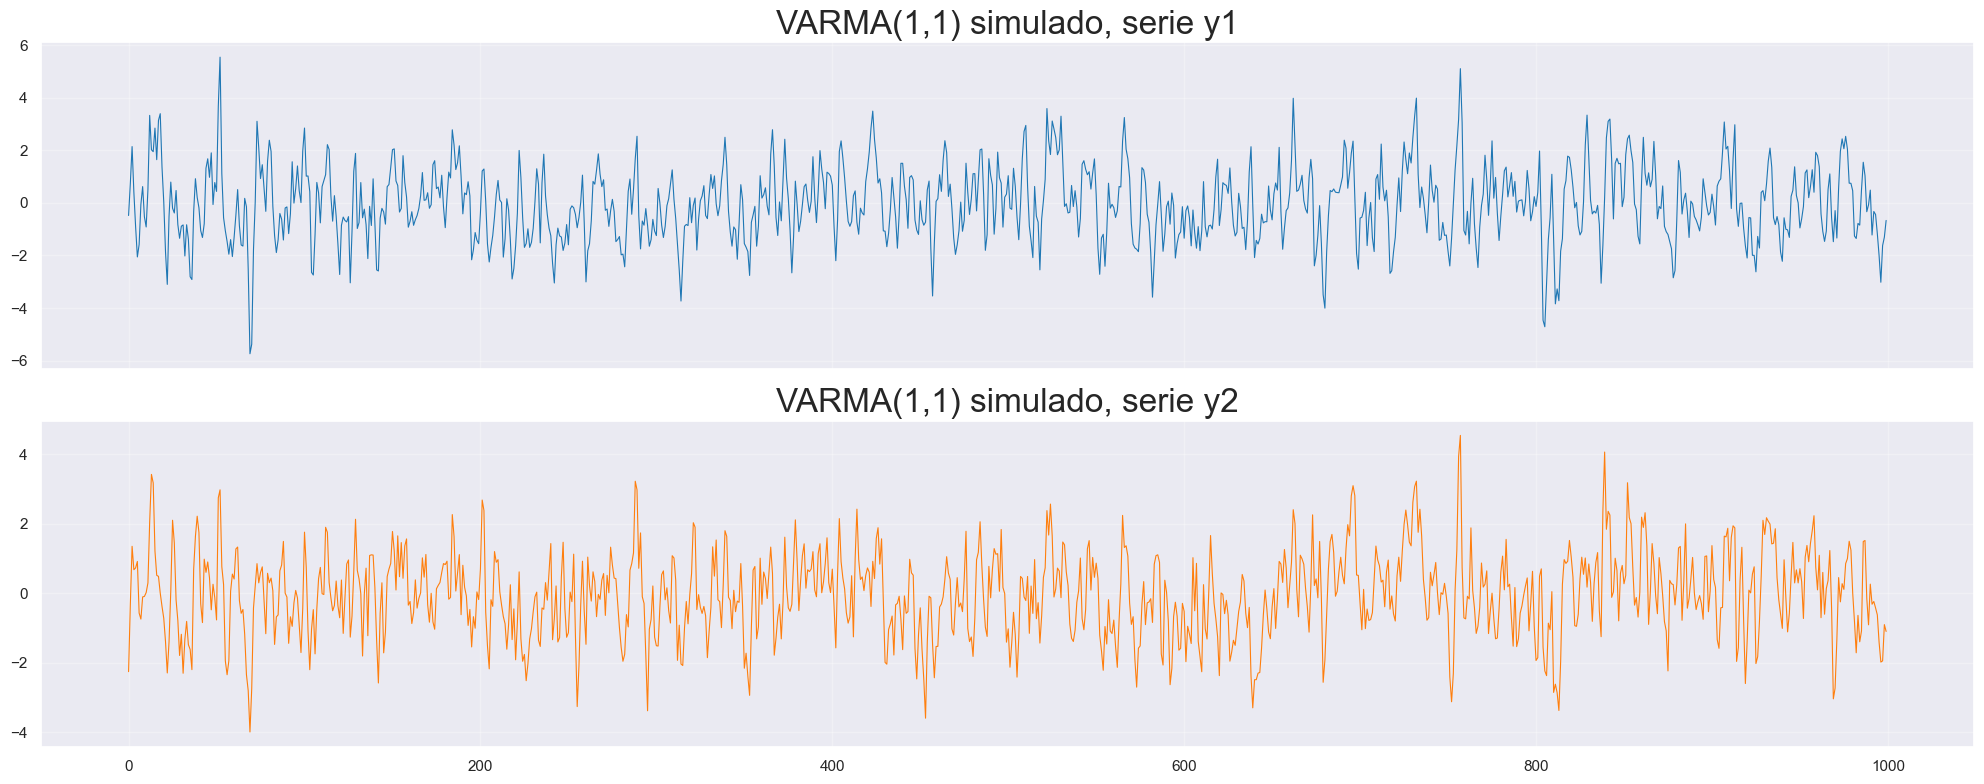

In [70]:
fig, axes = plt.subplots(2, 1, figsize=(20, 8), sharex=True)
for ax, col, color in zip(axes, ['y1', 'y2'], ['tab:blue', 'tab:orange']):
    ax.plot(df_varma[col], color=color, lw=0.8)
    ax.set_title(f'VARMA(1,1) simulado, serie {col}', size=24)
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

Las dos series oscilan alrededor de cero, sin tendencia y con una varianza que se mantiene. También se ve que suben y bajan bastante juntas, que es lo que espero por la correlación de los shocks y por los términos cruzados de $\Phi_1$.

### Verificación

Empiezo con Dickey-Fuller sobre cada serie.

In [71]:
adf_test(df_varma['y1'], 'VARMA(1,1), y1')
adf_test(df_varma['y2'], 'VARMA(1,1), y2')

Prueba de Dickey-Fuller aumentada: VARMA(1,1), y1
Estadístico ADF       -1.290807e+01
p-valor                4.112362e-24
# rezagos usados       3.000000e+00
# observaciones        9.960000e+02
valor crítico (1%)    -3.436933e+00
valor crítico (5%)    -2.864446e+00
valor crítico (10%)   -2.568317e+00
... se rechaza H0, la serie no tiene raíz unitaria y es estacionaria

Prueba de Dickey-Fuller aumentada: VARMA(1,1), y2
Estadístico ADF       -1.627876e+01
p-valor                3.429065e-29
# rezagos usados       1.000000e+00
# observaciones        9.980000e+02
valor crítico (1%)    -3.436919e+00
valor crítico (5%)    -2.864440e+00
valor crítico (10%)   -2.568314e+00
... se rechaza H0, la serie no tiene raíz unitaria y es estacionaria



Las dos son estacionarias, como predicen las raíces de $\det(I - \Phi_1 L)$.

Ahora veamos la dependencia cruzada. Para tener los valores teóricos reemplazo hacia atrás y escribo el VARMA como un MA infinito

$$\bar X_t = \sum_{j \ge 0} \Psi_j\,\bar\varepsilon_{t-j}, \qquad \Psi_0 = I, \qquad \Psi_1 = \Phi_1 + \Theta_1, \qquad \Psi_j = \Phi_1 \Psi_{j-1} \quad (j \ge 2).$$

Como los shocks de distintos instantes no están correlacionados, solo contribuyen los términos que comparten el mismo shock, así que

$$\Gamma(0) = \operatorname{Var}(\bar X_t) = \sum_{j \ge 0} \Psi_j\,\Sigma\,\Psi_j', \qquad \Gamma(1) = E[\bar X_t \bar X_{t-1}'] = \sum_{j \ge 0} \Psi_{j+1}\,\Sigma\,\Psi_j'.$$

Las $\Psi_j$ se achican a la mitad en cada paso, así que corto la suma en 50 términos. Con eso comparo las varianzas y las correlaciones teóricas con las muestrales.

In [72]:
# pesos del MA infinito
psi = [np.eye(2), Phi1 + Theta1]
for j in range(2, 50):
    psi.append(Phi1 @ psi[-1])
gamma0 = sum(p @ Sigma @ p.T for p in psi)
gamma1 = sum(psi[j + 1] @ Sigma @ psi[j].T for j in range(len(psi) - 1))

# las mismas matrices estimadas sobre la serie simulada
x = df_varma.values - df_varma.values.mean(axis=0)
gamma0_m = x.T @ x / len(x)
gamma1_m = x[1:].T @ x[:-1] / len(x)

def resumen(g0, g1):
    d = np.sqrt(np.diag(g0))
    return [g0[0, 0], g0[1, 1], g0[0, 1] / (d[0] * d[1]),
            g1[0, 0] / d[0] ** 2, g1[1, 1] / d[1] ** 2,
            g1[0, 1] / (d[0] * d[1]), g1[1, 0] / (d[0] * d[1])]

y1, y2 = df_varma['y1'], df_varma['y2']
filas = ['Var(X_t)', 'Var(Y_t)', 'corr(X_t, Y_t)', 'corr(X_t, X_t-1)',
         'corr(Y_t, Y_t-1)', 'corr(X_t, Y_t-1)', 'corr(Y_t, X_t-1)']
pd.DataFrame({'teórica': resumen(gamma0, gamma1), 'muestral': resumen(gamma0_m, gamma1_m)}, index=filas).round(3)

,teórica,muestral
Var(X_t),2.155,1.986
Var(Y_t),1.648,1.498
"corr(X_t, Y_t)",0.620,0.561
"corr(X_t, X_t-1)",0.686,0.673
"corr(Y_t, Y_t-1)",0.608,0.611
"corr(X_t, Y_t-1)",0.468,0.433
"corr(Y_t, X_t-1)",0.455,0.392


Las correlaciones muestrales quedan cerca de las teóricas, en general un poco por debajo, y las varianzas muestrales también dan algo más chicas. Con 1000 datos de una serie persistente eso es esperable, y además en esta corrida los shocks salieron un poco menos correlacionados que 0,5. Notemos que la correlación de cada serie con el rezago de la otra es bastante alta, aunque menor que la autocorrelación de cada una. Eso viene en parte de los términos cruzados de $\Phi_1$ y en parte de que las dos series ya están correlacionadas en el mismo instante.

Miro también la ACF de cada serie y la correlación cruzada en varios rezagos.

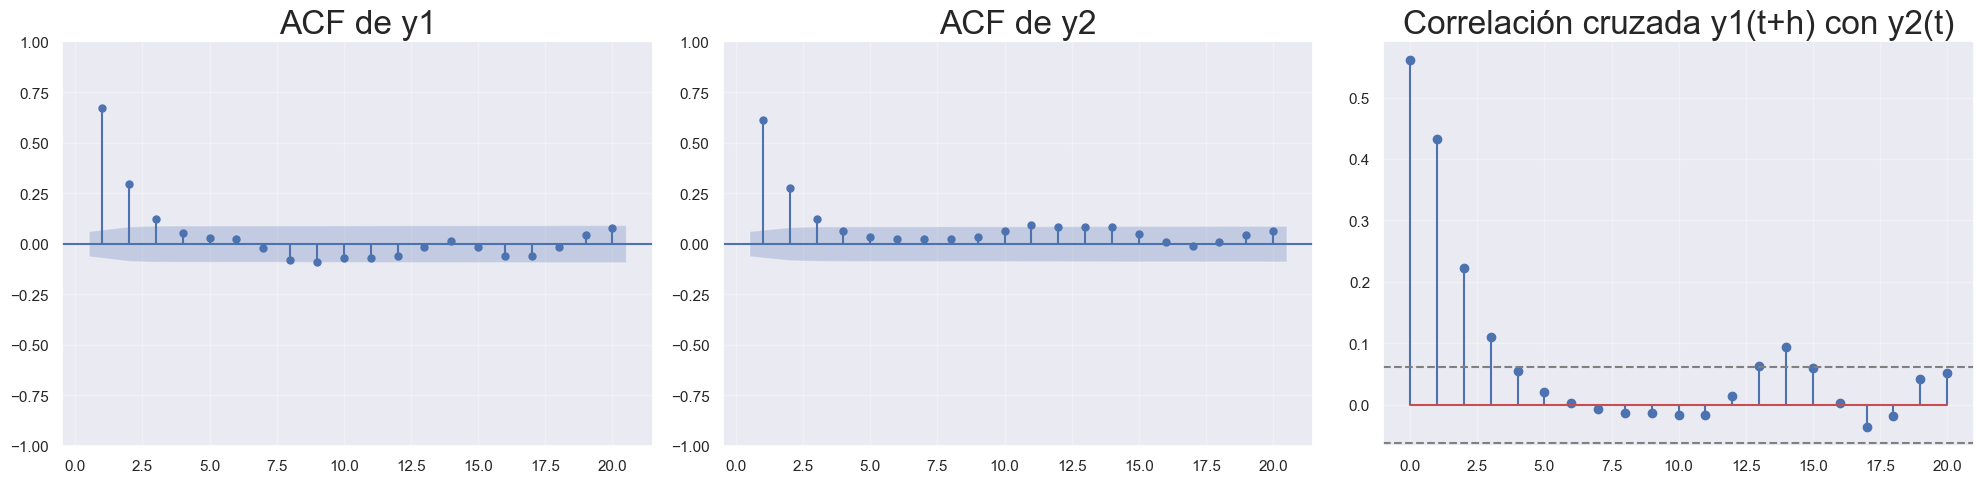

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sgt.plot_acf(y1, lags=20, zero=False, ax=axes[0])
axes[0].set_title('ACF de y1', size=24)
sgt.plot_acf(y2, lags=20, zero=False, ax=axes[1])
axes[1].set_title('ACF de y2', size=24)

# sts.ccf(x, y)[h] estima corr(x_{t+h}, y_t), acá corr(y1_{t+h}, y2_t)
ccf_12 = sts.ccf(y1, y2, adjusted=False)[:21]
axes[2].stem(range(21), ccf_12)
axes[2].axhline(1.96 / np.sqrt(n), color='gray', ls='--')
axes[2].axhline(-1.96 / np.sqrt(n), color='gray', ls='--')
axes[2].set_title('Correlación cruzada y1(t+h) con y2(t)', size=24)
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

Las ACF decaen rápido, como corresponde a una parte autorregresiva con autovalores chicos. La correlación cruzada arranca alta en $h=0$ y se apaga en unos tres rezagos, o sea que el vínculo entre las dos series se arrastra algunos períodos y después desaparece.

Por último ajusto un VARMAX(1,1) sobre las dos series, igual que en la clase pero con `trend='n'` porque simulo con media cero.

In [74]:
res_varma = VARMAX(df_varma, order=(1, 1), trend='n').fit(maxiter=1000, disp=False)
res_varma.summary()

Dep. Variable:,"['y1', 'y2']",No. Observations:,1000
Model:,"VARMA(1,1)",Log Likelihood,-2652.729
Date:,"Tue, 17 Nov 2026",AIC,5327.458
Time:,16:49:46,BIC,5381.444
Sample:,0,HQIC,5347.977
,- 1000,,
Covariance Type:,opg,,
Ljung-Box (L1) (Q):,"0.01, 0.00",Jarque-Bera (JB):,"0.34, 0.57"
Prob(Q):,"0.91, 1.00",Prob(JB):,"0.84, 0.75"
Heteroskedasticity (H):,"0.97, 1.03",Skew:,"0.00, -0.00"
Prob(H) (two-sided):,"0.75, 0.77",Kurtosis:,"3.09, 2.88"


En la tabla, `L1.y2.y1` es el coeficiente de $Y_{t-1}$ en la ecuación de $X_t$, o sea $(\Phi_1)_{12}$, y `L1.e(y2).y1` es el de $\varepsilon_{2,t-1}$, o sea $(\Theta_1)_{12}$. Para $\Sigma$, VARMAX estima su factor de Cholesky $P$ (con $PP' = \Sigma$), así que los valores reales de los tres `sqrt.*` salen de `np.linalg.cholesky(Sigma)`.

In [75]:
P = np.linalg.cholesky(Sigma)
reales_varma = {
    'L1.y1.y1': Phi1[0, 0], 'L1.y2.y1': Phi1[0, 1],
    'L1.y1.y2': Phi1[1, 0], 'L1.y2.y2': Phi1[1, 1],
    'L1.e(y1).y1': Theta1[0, 0], 'L1.e(y2).y1': Theta1[0, 1],
    'L1.e(y1).y2': Theta1[1, 0], 'L1.e(y2).y2': Theta1[1, 1],
    'sqrt.var.y1': P[0, 0], 'sqrt.cov.y1.y2': P[1, 0], 'sqrt.var.y2': P[1, 1],
}
tabla_parametros(reales_varma, res_varma)

,real,estimado,IC 95% inf,IC 95% sup,real dentro del IC
parámetro,,,,,
L1.y1.y1,0.400,0.401,0.306,0.496,True
L1.y2.y1,0.100,0.097,-0.023,0.217,True
L1.y1.y2,0.150,0.113,0.029,0.197,True
L1.y2.y2,0.350,0.371,0.255,0.487,True
L1.e(y1).y1,0.500,0.459,0.370,0.548,True
L1.e(y2).y1,0.000,0.022,-0.093,0.136,True
L1.e(y1).y2,0.000,-0.027,-0.124,0.070,True
L1.e(y2).y2,0.250,0.295,0.174,0.417,True
sqrt.var.y1,1.000,0.981,0.938,1.024,True


Diez de los once valores reales caen dentro de su intervalo de confianza al 95 %. El que queda afuera es `sqrt.cov.y1.y2`, que se estima por debajo de 0,5 y cuyo intervalo se queda corto por poco. Lo atribuyo al muestreo, porque la correlación muestral de los shocks que generé ya daba menos de 0,5, y además con once intervalos al 95 % es esperable que alrededor de uno no contenga al valor real.

Me queda ver que los residuos de cada ecuación sean ruido blanco.

Ljung-Box sobre los residuos de y1
    lb_stat  lb_pvalue
10  10.6754     0.3834
20  25.0247     0.2005 

Ljung-Box sobre los residuos de y2
    lb_stat  lb_pvalue
10   1.4778     0.9990
20  13.0672     0.8745 



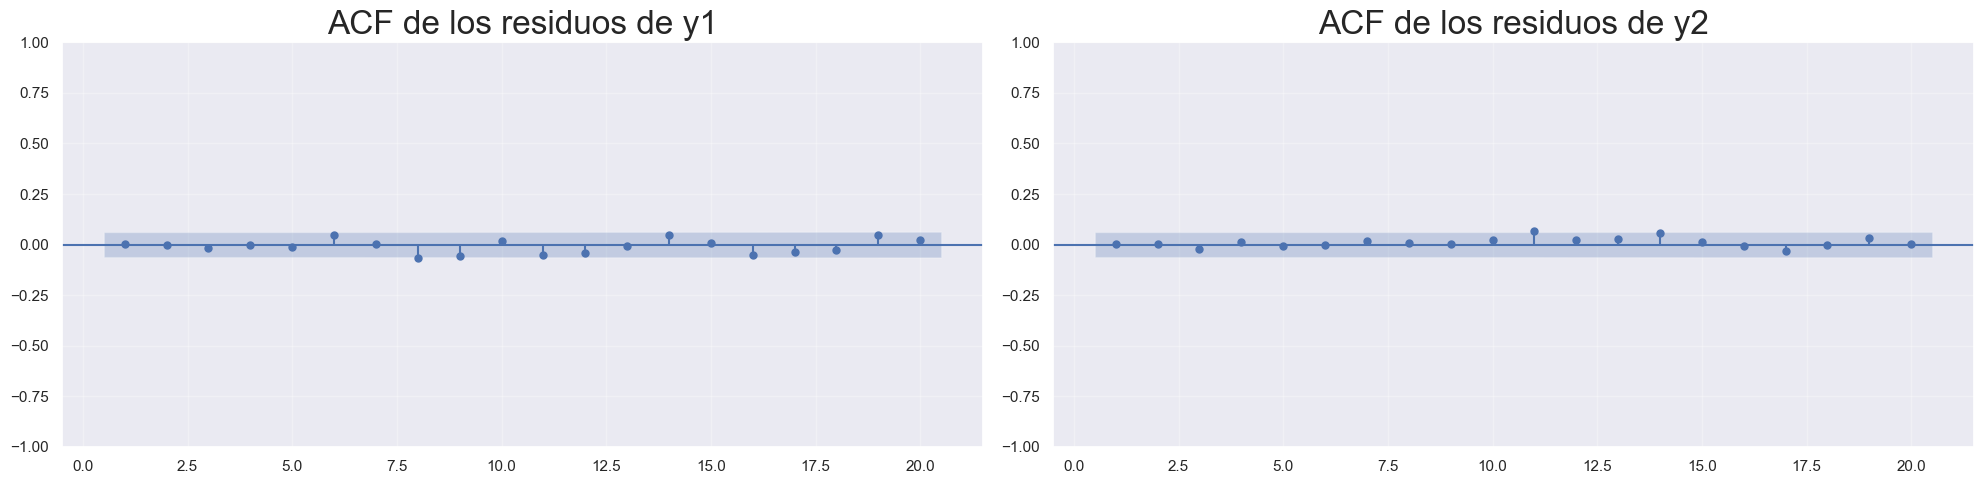

In [76]:
for col in ['y1', 'y2']:
    print(f'Ljung-Box sobre los residuos de {col}')
    print(acorr_ljungbox(res_varma.resid[col], lags=[10, 20]).round(4).to_string(), '\n')

fig, axes = plt.subplots(1, 2, figsize=(20, 5))
for ax, col in zip(axes, ['y1', 'y2']):
    sgt.plot_acf(res_varma.resid[col], lags=20, zero=False, ax=ax)
    ax.set_title(f'ACF de los residuos de {col}', size=24)
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

Ljung-Box no rechaza la hipótesis de ruido blanco en ninguna de las dos ecuaciones y las ACF de los residuos quedan dentro de las bandas salvo algún rezago suelto que apenas se asoma, así que el VARMA(1,1) captura la dependencia temporal de las series.

Entonces las series simuladas cumplen con el modelo. Son estacionarias, como dicen las raíces enteras de $\det(I - \Phi_1 L)$, y sus correlaciones propias y cruzadas se parecen a las teóricas que salen del MA infinito. Al volver a estimar el VARMAX recupero todas las entradas de $\Phi_1$ y $\Theta_1$ dentro de sus intervalos de confianza, la covarianza de los shocks con un desvío chico que atribuyo al muestreo, y residuos sin estructura. Además el ajuste devolvió por su cuenta una $\Theta_1$ prácticamente diagonal.

## 5. GARCH(1,1)

### Planteo

Los modelos anteriores describen la media de la serie, el GARCH describe su varianza condicional. Con la notación de clase y media cero, $\mu_t = 0$, un GARCH(1,1) es

$$
X_t = \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t, \qquad z_t \overset{iid}{\sim} N(0,1), \qquad
\sigma_t^2 = \alpha_0 + \alpha_1\, \varepsilon_{t-1}^2 + \beta_1\, \sigma_{t-1}^2 ,
$$

y elijo $\alpha_0 = 1$, $\alpha_1 = 0{,}25$ y $\beta_1 = 0{,}25$. Para que la varianza sea positiva pido $\alpha_0 > 0$ y $\alpha_1, \beta_1 \geq 0$, y para que sea estacionario $\alpha_1 + \beta_1 < 1$, que acá vale 0,5. O sea que el efecto de un shock sobre $\sigma_t^2$ se reduce a la mitad en cada paso, así que espero rachas de volatilidad cortas. La librería `arch` llama `omega` a $\alpha_0$.

Tomando esperanza en la ecuación de $\sigma_t^2$, y como en régimen estacionario $E(\varepsilon_t^2) = E(\sigma_t^2) = \sigma^2$ no depende de $t$, queda

$$
\sigma^2 = \alpha_0 + \alpha_1 \sigma^2 + \beta_1 \sigma^2 \quad\Rightarrow\quad \sigma^2 = \frac{\alpha_0}{1-\alpha_1-\beta_1} = \frac{1}{0{,}5} = 2 .
$$

Como $E(z_t) = 0$, la serie $\varepsilon_t$ no tiene autocorrelación, pero $\varepsilon_t^2$ sí. Llamando $\nu_t = \varepsilon_t^2 - \sigma_t^2$, que no tiene autocorrelación, y reemplazando en la ecuación de la varianza, $\varepsilon_t^2$ sigue un ARMA(1,1)

$$
\varepsilon_t^2 = \alpha_0 + (\alpha_1 + \beta_1)\, \varepsilon_{t-1}^2 + \nu_t - \beta_1\, \nu_{t-1},
$$

con polinomios $I - 0{,}5L$ y $I - 0{,}25L$, de raíces 2 y 4. Su ACF teórica se divide por 2 en cada rezago, $\rho(h) = 0{,}5^{\,h-1}\rho(1)$. Además $\varepsilon_t$ tiene colas más pesadas que la normal, con curtosis teórica

$$
\kappa = \frac{3\left(1-(\alpha_1+\beta_1)^2\right)}{1-(\alpha_1+\beta_1)^2-2\alpha_1^2} = 3{,}6 > 3 .
$$

### Simulación

Recorro la ecuación a mano. Arranco $\sigma_0^2$ en la varianza incondicional, saco todos los $z_t$ de una vez y en cada paso calculo primero $\sigma_t^2$ con el $\varepsilon_{t-1}$ y el $\sigma_{t-1}^2$ anteriores, y después $\varepsilon_t = \sigma_t z_t$. Tiro los primeros 500 valores.

In [77]:
rng = np.random.default_rng(7)

omega, alpha, beta = 1, 0.25, 0.25
n, burn = 2000, 500
var_incond = omega / (1 - alpha - beta)

z = rng.standard_normal(n + burn)
sigma2 = np.zeros(n + burn)
r = np.zeros(n + burn)
sigma2[0] = var_incond
r[0] = np.sqrt(sigma2[0]) * z[0]
for t in range(1, n + burn):
    sigma2[t] = omega + alpha * r[t - 1]**2 + beta * sigma2[t - 1]
    r[t] = np.sqrt(sigma2[t]) * z[t]

# descarto el burn-in
r = r[burn:]
sigma2 = sigma2[burn:]
serie_garch = pd.Series(r)

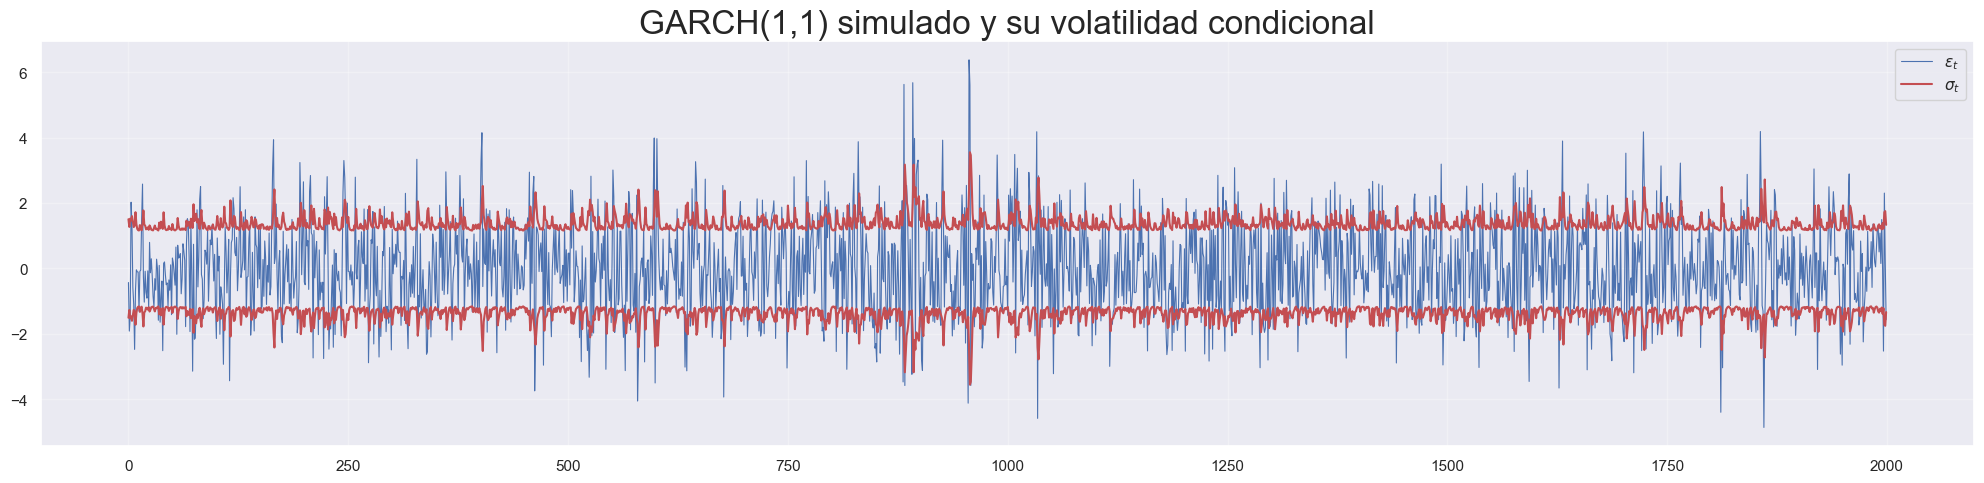

In [78]:
fig, ax = plt.subplots(figsize=(20, 5))
ax.plot(r, lw=0.8, label='$\\varepsilon_t$')
ax.plot(np.sqrt(sigma2), color='C3', lw=1.5, label='$\\sigma_t$')
ax.plot(-np.sqrt(sigma2), color='C3', lw=1.5)
ax.set_title('GARCH(1,1) simulado y su volatilidad condicional', size=24)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

Se ven rachas de volatilidad, aunque cortas. Cuando aparece un shock grande $\sigma_t$ salta y los valores que siguen también tienden a salir grandes, pero a los pocos pasos la volatilidad vuelve a su nivel medio, como esperaba con $\alpha_1 + \beta_1 = 0{,}5$. No hay tramos largos de calma o de agitación como los de una serie financiera, donde la persistencia suele ser mucho más alta. La serie oscila siempre alrededor de cero.

### Verificación

Primero la prueba de Dickey-Fuller y los momentos, comparando la varianza y la curtosis muestrales con las teóricas.

In [79]:
from scipy import stats

kurt_teo = 3 * (1 - (alpha + beta)**2) / (1 - (alpha + beta)**2 - 2 * alpha**2)

adf_test(r, 'GARCH(1,1)')
print(f'Media muestral       {r.mean():.4f}   (teórica 0)')
print(f'Varianza muestral    {r.var():.4f}   (teórica {var_incond:.4f})')
print(f'Curtosis muestral    {stats.kurtosis(r, fisher=False):.4f}   (teórica {kurt_teo:.4f})')

Prueba de Dickey-Fuller aumentada: GARCH(1,1)
Estadístico ADF         -43.199013
p-valor                   0.000000
# rezagos usados          0.000000
# observaciones        1999.000000
valor crítico (1%)       -3.433625
valor crítico (5%)       -2.862987
valor crítico (10%)      -2.567540
... se rechaza H0, la serie no tiene raíz unitaria y es estacionaria

Media muestral       -0.0006   (teórica 0)
Varianza muestral    1.9609   (teórica 2.0000)
Curtosis muestral    3.4538   (teórica 3.6000)


La prueba rechaza la raíz unitaria, así que la serie es estacionaria como corresponde con $\alpha_1 + \beta_1 < 1$. La media da cerca de cero y la varianza cerca de 2. La curtosis muestral sale mayor que 3, o sea que las colas son más pesadas que las de una normal aunque los $z_t$ sean normales. No espero que coincida exacto con la teórica porque la curtosis muestral depende mucho de los pocos valores extremos y converge despacio.

Ahora miro la correlación. Espero que la ACF de $\varepsilon_t$ no tenga nada significativo y que la de $\varepsilon_t^2$ sí.

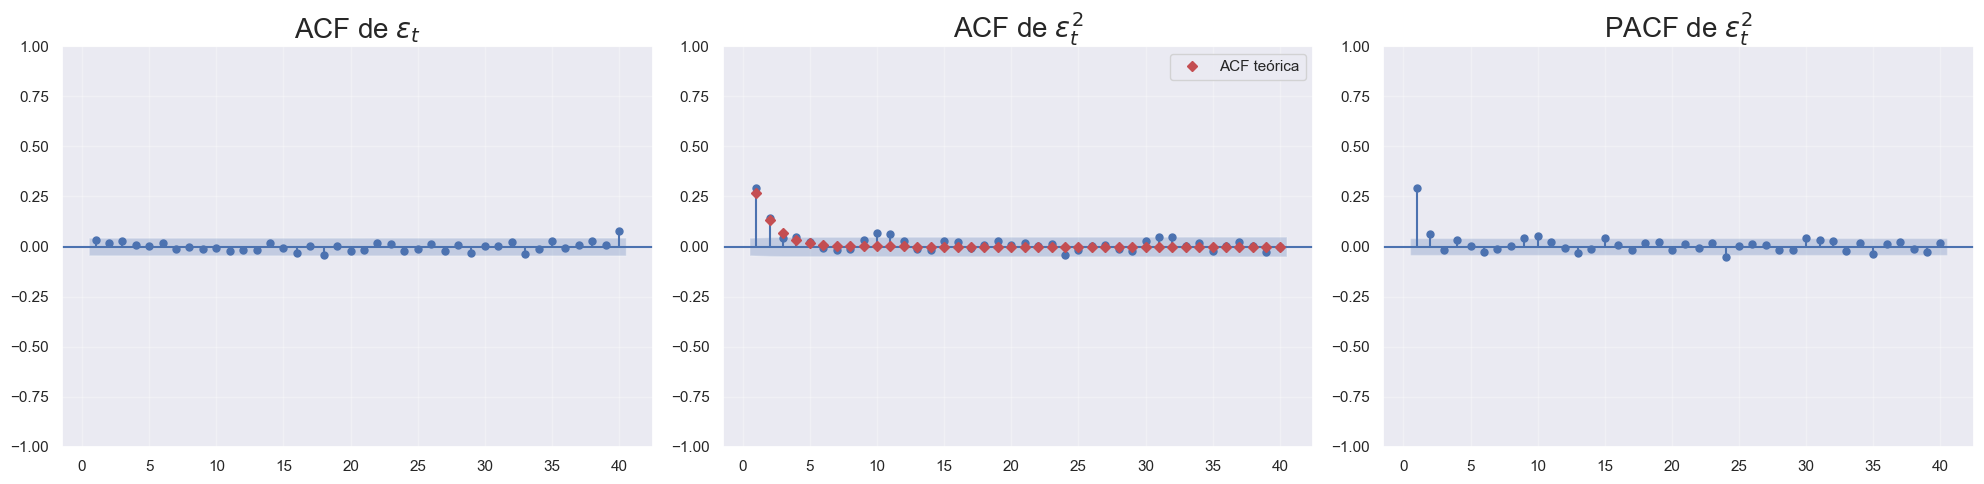

In [80]:
lags = 40
h = np.arange(1, lags + 1)
rho1 = alpha * (1 - alpha * beta - beta**2) / (1 - 2 * alpha * beta - beta**2)
acf_teo_r2 = rho1 * (alpha + beta)**(h - 1)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sgt.plot_acf(r, lags=lags, zero=False, ax=axes[0])
axes[0].set_title('ACF de $\\varepsilon_t$', size=20)
sgt.plot_acf(r**2, lags=lags, zero=False, ax=axes[1])
axes[1].plot(h, acf_teo_r2, 'D', color='C3', ms=5, label='ACF teórica')
axes[1].set_title('ACF de $\\varepsilon_t^2$', size=20)
axes[1].legend()
sgt.plot_pacf(r**2, lags=lags, zero=False, method='ols', ax=axes[2])
axes[2].set_title('PACF de $\\varepsilon_t^2$', size=20)
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

In [81]:
print('Ljung-Box sobre ε_t')
print(acorr_ljungbox(r, lags=[10, 20]))
print('\nLjung-Box sobre ε_t^2')
print(acorr_ljungbox(r**2, lags=[10, 20]))

Ljung-Box sobre ε_t
      lb_stat  lb_pvalue
10   6.046823   0.811314
20  16.146132   0.707518

Ljung-Box sobre ε_t^2
       lb_stat     lb_pvalue
10  233.072801  1.947840e-44
20  247.945613  2.964218e-41


La ACF de $\varepsilon_t$ queda prácticamente toda dentro de las bandas (si se asoma algún rezago suelto es lo esperable al mirar 40 al 5 %) y Ljung-Box no rechaza que sea ruido blanco, así que la serie no tiene estructura en la media. Con $\varepsilon_t^2$ pasa lo contrario. Su ACF tiene los primeros rezagos claramente significativos y después cae rápido a cero, siguiendo de cerca a la teórica. La PACF de $\varepsilon_t^2$ también tiene los primeros rezagos fuera de las bandas y Ljung-Box rechaza con un p-valor prácticamente nulo. O sea que los valores no están correlacionados pero su tamaño sí, que es lo que se conoce como efecto ARCH y es justo lo que dice el modelo.

Ahora estimo un GARCH(1,1) con media cero sobre la serie, sin decirle los parámetros.

In [82]:
res_garch = arch_model(serie_garch, mean='Zero', vol='GARCH', p=1, q=1).fit(disp='off')
res_garch.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                       Zero Mean - GARCH Model Results                        
==============================================================================
Dep. Variable:                   None   R-squared:                       0.000
Mean Model:                 Zero Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3460.51
Distribution:                  Normal   AIC:                           6927.02
Method:            Maximum Likelihood   BIC:                           6943.82
                                        No. Observations:                 2000
Date:                Tue, Nov 17 2026   Df Residuals:                     2000
Time:                        16:49:47   Df Model:                            0
                             Volatility Model                             
==========================================================================
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
omega          1.1019      0.183      6.017  1.774e-09   [  0.743,  1.461]
alpha[1]       0.2154  3.293e-02      6.542  6.053e-11   [  0.151,  0.280]
beta[1]        0.2172      0.104      2.088  3.682e-02 [1.329e-02,  0.421]
==========================================================================

Covariance estimator: robust
"""

In [83]:
tabla_parametros({'omega': omega, 'alpha[1]': alpha, 'beta[1]': beta}, res_garch)

,real,estimado,IC 95% inf,IC 95% sup,real dentro del IC
parámetro,,,,,
omega,1.00,1.102,0.743,1.461,True
alpha[1],0.25,0.215,0.151,0.280,True
beta[1],0.25,0.217,0.013,0.421,True


Los tres valores reales caen dentro de su intervalo de confianza al 95 %. El intervalo de $\beta_1$ sale bastante más ancho que los otros, y tiene sentido porque con poca persistencia la serie da poca información para separar el efecto de $\sigma_{t-1}^2$ del de $\alpha_0$. Para cerrar miro los residuos estandarizados $\hat z_t = \varepsilon_t / \hat\sigma_t$. Si el modelo capturó bien la volatilidad, $\hat z_t^2$ ya no debería tener autocorrelación.

Ljung-Box sobre los residuos estandarizados al cuadrado
      lb_stat  lb_pvalue
10   8.333237   0.596322
20  20.020824   0.456628


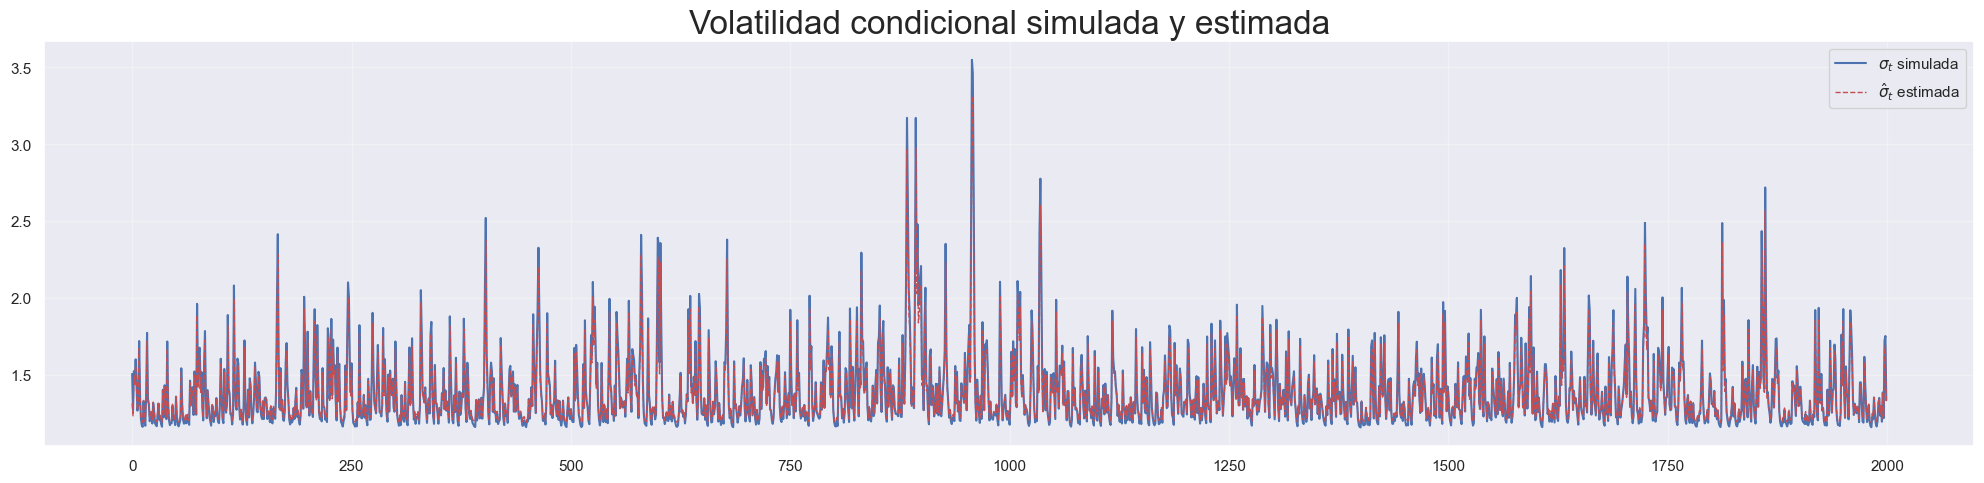

In [84]:
z_est = res_garch.std_resid
print('Ljung-Box sobre los residuos estandarizados al cuadrado')
print(acorr_ljungbox(z_est**2, lags=[10, 20]))

fig, ax = plt.subplots(figsize=(20, 5))
ax.plot(np.sqrt(sigma2), lw=1.5, label='$\\sigma_t$ simulada')
ax.plot(res_garch.conditional_volatility, color='C3', lw=1, ls='--', label='$\\hat\\sigma_t$ estimada')
ax.set_title('Volatilidad condicional simulada y estimada', size=24)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

Ljung-Box sobre $\hat z_t^2$ ya no rechaza, así que la autocorrelación que tenía $\varepsilon_t^2$ quedó toda explicada por la ecuación de $\sigma_t^2$. Y la volatilidad estimada prácticamente se superpone con la que uso para simular.

Entonces la serie cumple con el GARCH(1,1). Es estacionaria y en media se comporta como un ruido blanco, pero sus cuadrados se autocorrelacionan con el decaimiento que predice el modelo y sus colas son más pesadas que las de la normal. Al estimar recupero $\alpha_0$, $\alpha_1$ y $\beta_1$ dentro de sus intervalos, y los residuos estandarizados ya no tienen efecto ARCH. Este caso también muestra que mirar la ACF de una serie no alcanza para decir que es ruido blanco, porque acá la ACF de $\varepsilon_t$ no muestra nada y sin embargo la serie tiene estructura en la varianza.

## Conclusiones

Simulé cinco series, un ARMA(2,1), un ARIMA(1,1,1), un SARIMA(1,0,0)(2,1,0)$_{12}$, un VARMA(1,1) bivariado y un GARCH(1,1). En todos los casos partí de la ecuación del modelo y la recorrí con una recursión explícita sobre un ruido gaussiano, descartando un burn-in para que la condición inicial no pese. Así cada valor de la serie sale de los anteriores exactamente como dice su modelo. Los coeficientes los elegí para que las raíces de los polinomios característicos sean enteras, así se lee directo que caen fuera del círculo unitario.

Después verifiqué que cada serie se comporta como dice su modelo. La prueba de Dickey-Fuller separó las series estacionarias de las que necesitan una diferencia, y las autocorrelaciones muestrales siguieron a las teóricas. Al volver a estimar cada modelo sin darle los parámetros, todos los valores reales cayeron dentro de sus intervalos de confianza al 95 % en el ARMA, el ARIMA, el SARIMA y el GARCH. En el VARMA cayeron diez de los once, y el que quedó afuera es un término de la covarianza de los shocks, que se explica por ruido de muestreo. En los cinco casos los residuos quedaron sin estructura. Como el modelo con el que generé cada serie recupera sus parámetros y no deja nada en los residuos, puedo decir que la serie sigue ese modelo.

El GARCH me sirvió además para ver una diferencia con los otros cuatro. En esos la estructura está en la media y se ve directo en la ACF de la serie, mientras que en el GARCH está en la varianza y solo aparece cuando miro los cuadrados.